# N2H validation in mammalian cells

In [1]:
import glob
import xlrd
import pandas as pd
import numpy as np
import os
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
inputs_dir = "../1_inputs/N2H_validation"
allele_inputs = "../../../1_allele_collection/3_outputs"
outputs_dir = "../3_outputs/N2H_validation/mammalian_N2H"
sqy2h_outputs_dir = "../3_outputs/sqY2H"
yN2H_output_dir = "../3_outputs/N2H_validation/yeast_N2H"

nlr_detection_threshold = 2.326

## Wild type pairwise test

In [3]:
import warnings
warnings.simplefilter("ignore")

sheets = [f'Feuil{i}' for i in range (1, 22)]

wt_res = {'Exp1_1':dict(), 'Exp1_2':dict(), 'Exp2_1':dict(), 'Exp2_2':dict()}

for file_name in glob.glob(f'{inputs_dir}/mammalian_N2H/mN2H_WTPWT/data/*'):
    if 'N2H' in file_name:
        file_name = file_name.replace('~$','')
        xp = f'{file_name.split("_")[-1][:-7]}_{file_name.split("_")[-1][-6]}'

        for sheet in sheets:

            df =  pd.read_excel(file_name, sheet_name=sheet)
            df.rename(columns={c:c.lower() for c in df}, inplace=True)

            for dest_pla, dest_well, RawData, NA in zip(df.dest_pla, df['dest_well.1'], df['raw data'], df['unnamed: 13']):
                if NA != 1:
                    wt_res[xp][(dest_pla,dest_well)] = RawData
                else:
                    wt_res[xp][(dest_pla,dest_well)] = np.nan

In [4]:
# Read in the plate layout file
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch']

retest_df = pd.read_csv(f'{inputs_dir}/mammalian_N2H/mapping_mn2h.csv', low_memory=False)
wt_df = retest_df[retest_df.standard_batch == 'N2HVUSWT'][col]

In [5]:
for xp in wt_res:
    wt_df[xp] = [wt_res[xp][(pla, pos)] for pla, pos in zip(wt_df.retest_pla, wt_df.retest_pos)]
    
wt_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in wt_df.columns}, inplace=True)
wt_df.rename(columns={'Exp1_1':'mN2H_xp1r1','Exp1_2':'mN2H_xp1r2','Exp2_1':'mN2H_xp2r1','Exp2_2':'mN2H_xp2r2'}, inplace=True)

wt_df['xp1'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp1r1, wt_df.mN2H_xp1r2)]
wt_df['xp2'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp2r1, wt_df.mN2H_xp2r2)]

In [6]:
# calculate normalized luminescence ratio
empty_N1_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp1))
empty_N2_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp1))

empty_N1_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp2))
empty_N2_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp2))

normalized_wt_df = wt_df[wt_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_wt_df['empty_N1_xp1'] = normalized_wt_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp1'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_wt_df['empty_N1_xp2'] = normalized_wt_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp2'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp2_d)

normalized_wt_df['NLR_xp1'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp1, normalized_wt_df.empty_N1_xp1, normalized_wt_df.empty_N2_xp1)]
normalized_wt_df['NLR_xp2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp2, normalized_wt_df.empty_N1_xp2, normalized_wt_df.empty_N2_xp2)]

df = normalized_wt_df[normalized_wt_df.variant_id == 'RRS']
normalized_wt_df['zNLR1'] = normalized_wt_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
normalized_wt_df['zNLR2'] = normalized_wt_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

normalized_wt_df['NLR'] = normalized_wt_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)

normalized_wt_df['pair'] = [tuple(sorted([n1,n2])) for n1,n2 in zip(normalized_wt_df.N1_symbol, normalized_wt_df.N2_symbol)]

In [7]:
# Count the number detected by gene for different thresholds
normalized_wt_df['detected_0'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-1])
normalized_wt_df['detected_1'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-2])
normalized_wt_df['detected_2'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-3])
normalized_wt_df['detected_3'] = normalized_wt_df.NLR.apply(lambda x: x > sorted(normalized_wt_df[normalized_wt_df.variant_id == 'RRS'].NLR.dropna().tolist())[-4])

by_gene_df = pd.DataFrame([pd.Series(dict(normalized_wt_df[(normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts())),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_0 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_1 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_2 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts()),
                           pd.Series(normalized_wt_df[normalized_wt_df.detected_3 & (normalized_wt_df.variant_id == 'wt')].N2_symbol.value_counts())
                           
                          ]).T

by_gene_df.columns = ['y2h', 'mn2h_0','mn2h_1','mn2h_2', 'mn2h_3']
by_gene_df.fillna(0, inplace=True)
by_gene_df.sort_values(by='mn2h_0', ascending=False, inplace=True)

In [8]:
# Write out files
normalized_wt_df.to_csv(f'{outputs_dir}/mN2H_wtpwt_raw.csv')
by_gene_df.to_csv(f'{outputs_dir}/mN2H_wtpwt_counts.csv')

normalized_wt_df[(normalized_wt_df.detected_3 == True) & (normalized_wt_df.variant_id == 'wt')].to_csv(f'{outputs_dir}/mN2H_wtpwt_positive_PPIs.csv') 

## Allele pairwise test

In [9]:
# Dictionaries to map plate layouts
xp1_mapping_d = {i: ((i - 1) // 3 + 1, (i - 1) % 3 + 1) for i in range(1, 70)}

xp2_mapping_d = {
    1: (1,1),  2: (1,2),  3: (1,3),  4: (2,1),  5: (2,2),  6: (2,3),  
    7: (3,1),  8: (3,2),  9: (3,3), 10: (4,1), 11: (4,2), 12: (4,3),  
    13: (7,1), 14: (7,2), 15: (7,3), 16: (6,1), 17: (6,2), 18: (6,3),  
    19: (5,1), 20: (5,2), 21: (5,3), 22: (9,1), 23: (9,2), 24: (9,3),  
    25: (10,1), 26: (10,2), 27: (10,3), 28: (11,1), 29: (11,2), 30: (11,3),  
    31: (12,1), 32: (12,2), 33: (12,3), 34: (13,1), 35: (13,2), 36: (13,3),  
    37: (14,1), 38: (14,2), 39: (14,3), 40: (15,1), 41: (15,2), 42: (15,3),  
    43: (16,1), 44: (16,2), 45: (16,3), 46: (17,1), 47: (17,2), 48: (17,3),  
    49: (18,1), 50: (18,2), 51: (18,3), 52: (19,1), 53: (19,2), 54: (19,3),  
    55: (20,1), 56: (20,2), 57: (20,3), 58: (21,1), 59: (21,2), 60: (21,3),  
    61: (22,1), 62: (22,2), 63: (22,3), 64: (23,1), 65: (23,2), 66: (23,3),  
    67: (8,1), 68: (8,2), 69: (8,3)
}

In [10]:
# Load in raw data for allele pairwise test (apwt) from the mammalian N2H validation assay
res = {'xp1':{1:{},2:{},3:{}},
        'xp2':{1:{},2:{},3:{}}
        }

for rep_id in ['1','2']:
    for i,elem in enumerate(glob.glob(f'{inputs_dir}/mammalian_N2H/mN2H_APWT/N2H_raw_replicat0{rep_id}/*')):
        pla = int(elem.split('-')[-1][1:-4])
        retest_pla, repeat = xp1_mapping_d[pla] if rep_id == '1' else xp2_mapping_d[pla]

        wb = xlrd.open_workbook(elem, encoding_override='ascii')  #ascii  #'iso-8859-1'
        df = pd.read_excel(wb, skiprows=24, skipfooter=0)
        if len(df) > 8:
            df = pd.read_excel(wb, skiprows=35, skipfooter=10)

        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')

                res[f'xp{rep_id}'][repeat][key] = value

In [11]:
# Read in the plate layout file
retest_df = pd.read_csv(f'{inputs_dir}/mammalian_N2H/mapping_mn2h.csv', low_memory=False)
retest_df = retest_df[retest_df.standard_batch == 'mN2Hapwtv2'].copy()
retest_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in retest_df.columns},inplace=True)

# Calculate normalized luminescence ratio
for xp in ['xp1','xp2']:
    for rep in [1,2,3]:
        retest_df[f'mN2H_{xp}r{rep}'] = [res[xp][rep][pla,pos] if (pla,pos) in res[xp][rep] else np.nan for pla,pos in zip(retest_df.retest_pla, retest_df.retest_pos)]

#discard measure if signal is 20% of those of 2 other replicates (it's never 5 fold more than the 2 other measures)    
retest_df['mN2H_xp1r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp2r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

xp_errors = {1:{(5,'E03')},
                2:{(5,'E03'),
                (13,'A05'),
                (13,'A06'),
                (13,'D06'),
                (14,'C01'),
                (14,'B04'),
                (14,'E06'),
                (14,'H06'),
                (14,'B08'),
                (14,'A10'),
                }
            }

retest_df['error1'] = [(p,w) in [(pla,well) for pla,well in xp_errors[1]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]
retest_df['error2'] = [(p,w) in [(pla,well) for pla,well in xp_errors[2]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]

retest_df['xp1'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['xp2'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

retest_df['xp1'] = [xp1 if not error else np.nan for xp1,error in zip(retest_df.xp1, retest_df.error1)]
retest_df['xp2'] = [xp2 if not error else np.nan for xp2,error in zip(retest_df.xp2, retest_df.error2)]

retest_df['xp_mean'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(retest_df.xp1, retest_df.xp2)]

In [12]:
# 1) Compute WT xp mean for empty_N1 variant per plate and N2_orf_id
empty1 = retest_df[retest_df.variant_id == 'empty_N1']
wt_map = (
    empty1[empty1['N2_mut_id'] == 0]
    .groupby(['retest_pla', 'N2_orf_id'])['xp_mean']
    .mean()
    .rename('wt_xp_mean')
    .reset_index()
)

# 2) Merge back into the empty1 subset and compute log10FC
empty1 = empty1.merge(wt_map, on=['retest_pla', 'N2_orf_id'], how='left')
empty1['log10fc_empty_N1'] = np.log10(empty1['xp_mean'] / empty1['wt_xp_mean'])

# 3) Attach this new column to the full retest_df
retest_df = retest_df.merge(
    empty1[['retest_pla', 'N2_orf_id', 'N2_mut_id', 'log10fc_empty_N1']],
    on=['retest_pla', 'N2_orf_id', 'N2_mut_id'],
    how='left'
)


In [13]:
empty1

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,wt_xp_mean,log10fc_empty_N1
0,92604.0,0.0,NaN,NaN,5001.0,NCK1,0.0,1.0,B01,mN2Hapwtv2,...,186214.0,208374.0,229324,False,False,133281.333333,2.079707e+05,170626.000000,170626.000000,0.000000
1,92607.0,0.0,NaN,NaN,4447.0,STAC3,0.0,1.0,E01,mN2Hapwtv2,...,15277.0,16560.0,18936,False,False,11384.000000,1.692433e+04,14154.166667,14154.166667,0.000000
2,92610.0,0.0,NaN,NaN,5887.0,ARMC1,0.0,1.0,H01,mN2Hapwtv2,...,87676.0,112795.0,132542,False,False,59592.666667,1.110043e+05,85298.500000,85298.500000,0.000000
3,92613.0,0.0,NaN,NaN,7186.0,ZC3HC1,0.0,1.0,C02,mN2Hapwtv2,...,1009609.0,1209527.0,1160934,False,False,840605.666667,1.126690e+06,983647.833333,983647.833333,0.000000
4,92616.0,0.0,NaN,NaN,5046.0,NQO2,0.0,1.0,F02,mN2Hapwtv2,...,54243.0,56299.0,64184,False,False,27121.333333,5.824200e+04,42681.666667,42681.666667,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
585,94662.0,0.0,NaN,NaN,13592.0,KRT4,0.0,23.0,H04,mN2Hapwtv2,...,3027.0,2732.0,2333,False,False,1307.666667,2.697333e+03,2002.500000,2002.500000,0.000000
586,94664.0,0.0,NaN,NaN,1063.0,SMN2,0.0,23.0,B05,mN2Hapwtv2,...,5127.0,6656.0,5845,False,False,3410.000000,5.876000e+03,4643.000000,4643.000000,0.000000
587,94666.0,0.0,NaN,NaN,3438.0,TMEM43,201183.0,23.0,D05,mN2Hapwtv2,...,1590.0,1504.0,1633,False,False,1117.666667,1.575667e+03,1346.666667,1445.000000,-0.030608
588,94671.0,0.0,NaN,NaN,4004.0,FADD,201387.0,23.0,A06,mN2Hapwtv2,...,7859.0,10015.0,9339,False,False,2814.333333,9.071000e+03,5942.666667,22947.000000,-0.586745


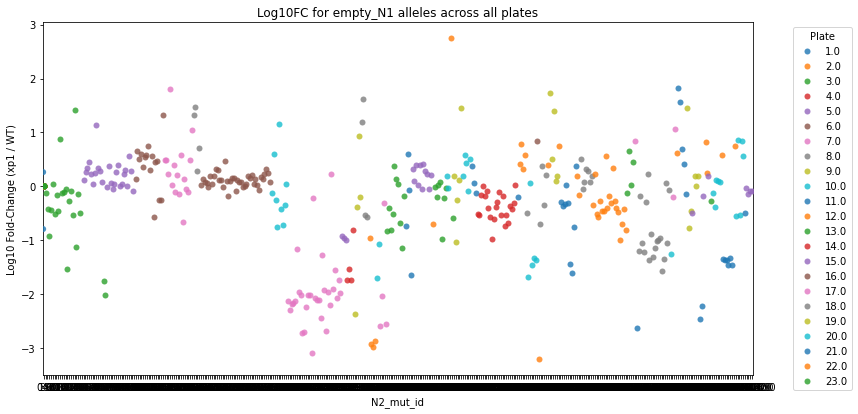

In [14]:
# 4) Plot all log10FC on a single stripplot, coloring by plate
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=empty1, 
    x='N2_mut_id', 
    y='log10fc_empty_N1', 
    hue='retest_pla', 
    dodge=True, 
    jitter=0.2, 
    palette='tab10',
    size=6,
    alpha=0.8
)
plt.xlabel('N2_mut_id')
plt.ylabel('Log10 Fold‑Change (xp1 / WT)')
plt.title('Log10FC for empty_N1 alleles across all plates')
plt.legend(title='Plate', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

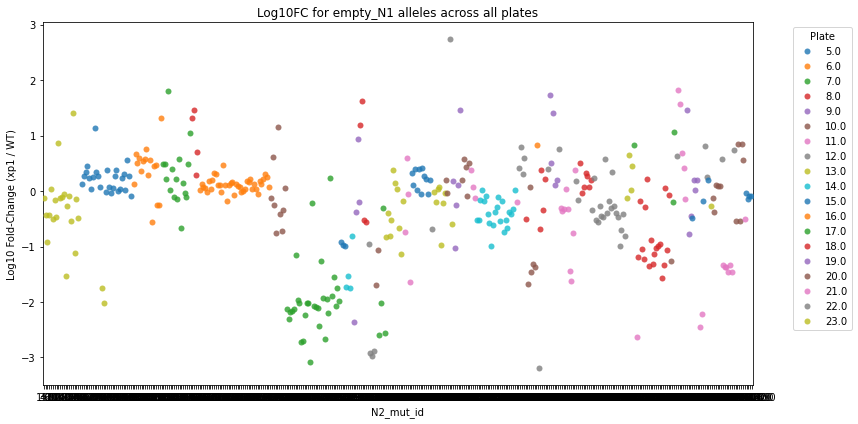

In [15]:
# 4) Plot all log10FC on a single stripplot, coloring by plate
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=empty1[empty1['N2_mut_id'] != 0], 
    x='N2_mut_id', 
    y='log10fc_empty_N1', 
    hue='retest_pla', 
    dodge=True, 
    jitter=0.2, 
    palette='tab10',
    size=6,
    alpha=0.8,
    # order=sorted(empty1[empty1['N2_mut_id'] != 0]['retest_pla'].unique())  # Order by retest_pla
)
plt.xlabel('N2_mut_id')
plt.ylabel('Log10 Fold‑Change (xp1 / WT)')
plt.title('Log10FC for empty_N1 alleles across all plates')
plt.legend(title='Plate', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

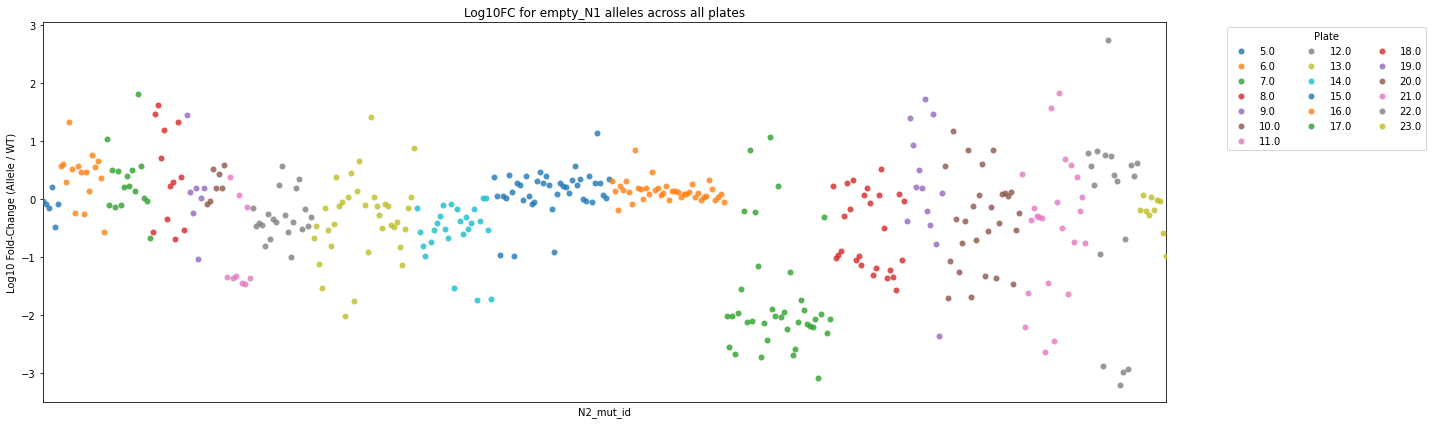

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Filter data
filtered_df = empty1[(empty1['N2_mut_id'] != 0) & (empty1['N2_mut_id'] == empty1['N2_mut_id'])]

# Sort N2_mut_id by retest_pla
ordered_ids = (
    filtered_df.groupby('retest_pla')['N2_mut_id']
    .unique()
    .explode()
    .dropna()
    .astype(str)
    .tolist()
)

# Remove duplicates while preserving order
ordered_ids = list(dict.fromkeys(ordered_ids))

# Convert N2_mut_id to string if needed for proper alignment with 'order'
filtered_df['N2_mut_id'] = filtered_df['N2_mut_id'].astype(str)

# Plot
plt.figure(figsize=(20, 6))
sns.stripplot(
    data=filtered_df,
    x='N2_mut_id',
    y='log10fc_empty_N1',
    hue='retest_pla',
    dodge=True,
    jitter=0.2,
    palette='tab10',
    size=6,
    alpha=0.8,
    order=ordered_ids
)
plt.xlabel('N2_mut_id')
plt.ylabel('Log10 Fold‑Change (Allele / WT)')
plt.title('Log10FC for empty_N1 alleles across all plates')
plt.legend(title='Plate', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=3)
plt.xticks([], [])
plt.tight_layout()
plt.show()

In [17]:
retest_df[retest_df.retest_pla == 16]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
1376,93975.0,0.0,NaN,NaN,100016069.0,KCNJ2,2612.0,16.0,A01,mN2Hapwtv2,...,1265.0,1842.0,2910.0,2610,False,False,1168.666667,2454.000000,1811.333333,0.311546
1377,93976.0,0.0,NaN,NaN,100016069.0,KCNJ2,2602.0,16.0,B01,mN2Hapwtv2,...,853.0,1529.0,1713.0,1621,False,False,779.333333,1621.000000,1200.166667,0.132789
1378,93977.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2620.0,16.0,C01,mN2Hapwtv2,...,4421.0,5225.0,5219.0,5010,False,False,4061.000000,5151.333333,4606.166667,-0.183774
1379,93978.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2643.0,16.0,D01,mN2Hapwtv2,...,3703.0,4869.0,4980.0,6558,False,False,3754.000000,5469.000000,4611.500000,0.218000
1380,93979.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2649.0,16.0,E01,mN2Hapwtv2,...,3746.0,4274.0,4820.0,5182,False,False,3463.000000,4758.666667,4110.833333,0.034308
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1464,94063.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2627.0,16.0,B12,mN2Hapwtv2,...,2137.0,1756.0,2131.0,2407,False,False,2188.333333,2098.000000,2143.166667,0.121610
1465,94064.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2650.0,16.0,C12,mN2Hapwtv2,...,2653.0,1953.0,2935.0,2542,False,False,2595.666667,2476.666667,2536.166667,-0.058929
1466,94065.0,0.0,NaN,NaN,100016069.0,KCNJ2,2604.0,16.0,D12,mN2Hapwtv2,...,1111.0,841.0,1032.0,1289,False,False,1070.333333,1054.000000,1062.166667,0.079740
1467,94066.0,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2622.0,16.0,E12,mN2Hapwtv2,...,3629.0,2763.0,3758.0,4310,False,False,3383.000000,3610.333333,3496.666667,0.103347


In [18]:

# Old version established by Jess and Flo

# empty_N1_xp1_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp1))
# empty_N2_xp1_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp1))

# empty_N1_xp2_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp2))
# empty_N2_xp2_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp2))



# Max fix - above is not taking empty replicates into account, the dict-zip approach only consider the last measurement

empty_N1_xp1_d = {}

for (N2_orf_id, N2_mut_id), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id']):
    empty_N1_xp1_d[(N2_orf_id, N2_mut_id)] = np.mean(df.xp1)

empty_N1_xp2_d = {}

for (N2_orf_id, N2_mut_id), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id']):
    empty_N1_xp2_d[(N2_orf_id, N2_mut_id)] = np.mean(df.xp2)
    
empty_N2_xp1_d = {}

for N1_orf_id, df in retest_df[retest_df.variant_id == 'empty_N2'].groupby('N1_orf_id'):
    empty_N2_xp1_d[N1_orf_id] = np.mean(df.xp1)

empty_N2_xp2_d = {}

for N1_orf_id, df in retest_df[retest_df.variant_id == 'empty_N2'].groupby('N1_orf_id'):
    empty_N2_xp2_d[N1_orf_id] = np.mean(df.xp2)

# Continue

# second approach, per plate

# empty_N1_xp1_d = {}

# for (N2_orf_id, N2_mut_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id', 'retest_pla']):
#     empty_N1_xp1_d[(N2_orf_id, N2_mut_id, retest_pla)] = np.mean(df.xp1)

# empty_N1_xp2_d = {}

# for (N2_orf_id, N2_mut_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N1'].groupby(['N2_orf_id', 'N2_mut_id', 'retest_pla']):
#     empty_N1_xp2_d[(N2_orf_id, N2_mut_id, retest_pla)] = np.mean(df.xp2)
    
# empty_N2_xp1_d = {}

# for (N1_orf_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N2'].groupby(['N1_orf_id','retest_pla']):
#     empty_N2_xp1_d[(N1_orf_id, retest_pla)] = np.mean(df.xp1)

# empty_N2_xp2_d = {}

# for (N1_orf_id, retest_pla), df in retest_df[retest_df.variant_id == 'empty_N2'].groupby(['N1_orf_id','retest_pla']):
#     empty_N2_xp2_d[(N1_orf_id, retest_pla)] = np.mean(df.xp2)



normalized_df = retest_df[retest_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_df.drop(columns=['error1','error2','mN2H_xp1r1','mN2H_xp1r2','mN2H_xp1r3','mN2H_xp2r1','mN2H_xp2r2','mN2H_xp2r3'], inplace=True)

normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp1'] = normalized_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp2'] = normalized_df.N1_orf_id.map(empty_N2_xp2_d)

# apply the pla method

# normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id,x.retest_pla], axis=1)
# normalized_df['empty_N2_xp1'] = normalized_df.apply(lambda x: empty_N2_xp1_d[x.N1_orf_id,x.retest_pla], axis=1)

# normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id, x.retest_pla], axis=1)
# normalized_df['empty_N2_xp2'] = normalized_df.apply(lambda x: empty_N2_xp2_d[x.N1_orf_id,x.retest_pla], axis=1)

# test for the empty based on z-score

# normalized_df['z_empty_N1_xp1'] = normalized_df.empty_N1_xp1.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)
# normalized_df['z_empty_N2_xp1'] = normalized_df.empty_N2_xp1.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)

# normalized_df['z_empty_N1_xp2'] = normalized_df.empty_N1_xp2.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)
# normalized_df['z_empty_N2_xp2'] = normalized_df.empty_N2_xp2.apply(lambda x: (np.log10(x)-empty_mean)/empty_std)

# zcols = [
#     'z_empty_N1_xp1','z_empty_N2_xp1',
#     'z_empty_N1_xp2','z_empty_N2_xp2'
# ]

# mask = normalized_df[zcols].abs().le(2).all(axis=1)

# normalized_df = normalized_df[mask].copy()

##

normalized_df['max_ctrl_r1'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['max_ctrl_r2'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

normalized_df['NLR1'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp1, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['NLR2'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp2, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

d = {0:1,1:0}
normalized_df['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(normalized_df.NLR1, normalized_df.NLR2))]
normalized_df['repeat_ratio_log2'] = normalized_df.repeat_ratio.apply(np.log2)

normalized_df['avg_NLR'] = [np.mean([nlr1, nlr2]) for nlr1,nlr2 in zip(normalized_df.NLR1, normalized_df.NLR2)]

# Max add
normalized_df['pair'] = list(zip(normalized_df.N2_orf_id, normalized_df.N1_orf_id))

std_nlr_variation = np.std(normalized_df['repeat_ratio_log2'])
avg_nlr_variation = np.mean(normalized_df['repeat_ratio_log2'])

normalized_df['repeat_zscore'] = normalized_df.repeat_ratio_log2.apply(lambda x: abs((x-avg_nlr_variation)/std_nlr_variation) >= 1)


In [19]:
# Get perturbation z-scores
allele_df = normalized_df.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()

df = normalized_df.query("variant_id == 'wt'")
df_wt = normalized_df.query("variant_id == 'wt'")

wt_NLR_d = {(r.N2_orf_id, r.N1_orf_id):r.avg_NLR for i,r in df.iterrows()}


allele_df['avg_WT_NLR'] = [wt_NLR_d.get((N2,N1), np.nan) for N2,N1 in zip(allele_df.N2_orf_id, allele_df.N1_orf_id)]
allele_df = allele_df[~allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.avg_NLR / allele_df.avg_WT_NLR

# Max add - Above approach doesn't take into account that multiple alleles/wt span across multiple plates
wt_pla_d = {((r.N2_orf_id, r.N1_orf_id), r.retest_pla):r.avg_NLR for _, r in df.iterrows()}
# allele_df['avg_WT_NLR_pla'] = [wt_pla_d.get(((N2,N1),pla), np.nan) for N2,N1,pla in zip(allele_df.N2_orf_id, allele_df.N1_orf_id, allele_df.retest_pla)]
# allele_df['AWT_ratio_pla'] = allele_df.avg_NLR / allele_df.avg_WT_NLR_pla
# allele_df['log2fc'] = np.log2(allele_df.avg_NLR / allele_df.avg_WT_NLR_pla)
allele_df['log2fc'] = np.log2(allele_df.avg_NLR / allele_df.avg_WT_NLR)

# Continue

df = normalized_df.query("variant_id == 'RRS' and avg_NLR < 200")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
allele_df['z_WT_NLR'] = allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= nlr_detection_threshold)

# Max add

# allele_df['z_WT_NLR_pla'] = allele_df.avg_WT_NLR_pla.apply(lambda x: (x-mean_rrs)/std_rrs)
# allele_df['WT_detected_pla'] = allele_df.z_WT_NLR_pla.apply(lambda x: x >= 2.326)


std_ratio = np.std(normalized_df.repeat_ratio_log2)
mean_ratio = np.mean(normalized_df.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=1.96 else 'decrease_ppi' if zp<=-1.96 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

In [20]:
allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,avg_NLR,pair,repeat_zscore,avg_WT_NLR,AWT_ratio,log2fc,z_WT_NLR,WT_detected,z_perturbation,z_cat
436,93035.0,2838.0,TMEM248,NaN,9634.0,CLDN19,216880.0,5.0,A08,mN2Hapwtv2,...,44.131987,"(9634.0, 2838.0)",False,15.997987,2.758596,1.463934,0.725847,False,1.455811,not_detected
438,93037.0,1198.0,TNFSF14,NaN,9634.0,CLDN19,216880.0,5.0,C08,mN2Hapwtv2,...,125.206005,"(9634.0, 1198.0)",False,71.134638,1.760127,0.815680,5.255818,True,0.807605,no_perturbation
444,93043.0,7201.0,RAD51D,NaN,13571.0,XRCC2,218098.0,5.0,A09,mN2Hapwtv2,...,149.433435,"(13571.0, 7201.0)",False,283.134878,0.527782,-0.921986,22.673542,True,-0.929932,no_perturbation
445,93044.0,9955.0,FCGR1A,NaN,9634.0,CLDN19,216880.0,5.0,B09,mN2Hapwtv2,...,300.129872,"(9634.0, 9955.0)",False,81.352606,3.689247,1.883326,6.095316,True,1.875172,no_perturbation
446,93045.0,56141.0,KRT31,NaN,55855.0,KRT2,219419.0,5.0,C09,mN2Hapwtv2,...,49.468494,"(55855.0, 56141.0)",True,3.108661,15.913120,3.992145,-0.333127,False,3.983833,not_detected
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2070,94669.0,138.0,MYD88,NaN,4004.0,FADD,201387.0,23.0,G05,mN2Hapwtv2,...,50.551065,"(4004.0, 138.0)",False,47.163573,1.071824,0.100068,3.286380,True,0.092047,no_perturbation
2075,94674.0,361.0,GRAMD2B,NaN,3438.0,TMEM43,201179.0,23.0,D06,mN2Hapwtv2,...,62.414735,"(3438.0, 361.0)",False,94.197838,0.662592,-0.593807,7.150667,True,-0.601777,no_perturbation
2080,94679.0,4105.0,KRT15,NaN,13592.0,KRT4,218110.0,23.0,A07,mN2Hapwtv2,...,38.687830,"(13592.0, 4105.0)",False,39.654231,0.975629,-0.035595,2.669420,True,-0.043606,no_perturbation
2083,94682.0,361.0,GRAMD2B,NaN,3438.0,TMEM43,201175.0,23.0,D07,mN2Hapwtv2,...,61.858924,"(3438.0, 361.0)",False,94.197838,0.656692,-0.606712,7.150667,True,-0.614681,no_perturbation


In [21]:
wt_NLR_d

{(9634.0, 1198.0): 71.13463752192112,
 (9634.0, 2758.0): 122.80009708745496,
 (13571.0, 7201.0): 283.1348782601766,
 (9634.0, 9955.0): 81.35260644855211,
 (9634.0, 7408.0): 1.8446919887521684,
 (9634.0, 147.0): 169.83142761506684,
 (55855.0, 56141.0): 3.108660799615839,
 (9634.0, 2838.0): 15.997986777820937,
 (7652.0, 7233.0): 8.093129493070627,
 (7652.0, 2615.0): 5.5871871288826185,
 (7652.0, 199.0): 16.366453666296273,
 (7652.0, 14387.0): 6.394524121759915,
 (7675.0, 7675.0): 143.02010576324307,
 (4062.0, 2012.0): 4.704581244826643,
 (4062.0, 4935.0): 13.555359677328862,
 (4062.0, 4946.0): 4.902415855662868,
 (4062.0, 11621.0): 4.206982141225426,
 (9866.0, 6520.0): 64.53859129025246,
 (4062.0, 12825.0): 2.462901299539321,
 (4062.0, 6446.0): 30.848519734562963,
 (4062.0, 8186.0): 13.394813779895838,
 (4062.0, 13628.0): 8.83343915394085,
 (4062.0, 5793.0): 63.17764309233708,
 (4062.0, 11130.0): 3.9423262022968197,
 (4062.0, 8165.0): 26.116078754782215,
 (3731.0, 3731.0): 76.33468791159

In [22]:
wt_pla_d

{((9634.0, 1198.0), 5.0): 71.13463752192112,
 ((9634.0, 2758.0), 5.0): 122.80009708745496,
 ((13571.0, 7201.0), 5.0): 283.1348782601766,
 ((9634.0, 9955.0), 5.0): 81.35260644855211,
 ((9634.0, 7408.0), 5.0): 1.8446919887521684,
 ((9634.0, 147.0), 5.0): 169.83142761506684,
 ((55855.0, 56141.0), 5.0): 3.108660799615839,
 ((9634.0, 2838.0), 5.0): 15.997986777820937,
 ((7652.0, 7233.0), 6.0): 14.144451344459004,
 ((7652.0, 2615.0), 6.0): 13.382337427446373,
 ((7652.0, 199.0), 6.0): 26.314845416282868,
 ((7652.0, 14387.0), 6.0): 15.496971642300183,
 ((7652.0, 7233.0), 7.0): 19.31667090183584,
 ((7652.0, 2615.0), 7.0): 21.369038420608963,
 ((7652.0, 199.0), 7.0): 32.373364260981674,
 ((7652.0, 14387.0), 7.0): 19.96905154349723,
 ((7652.0, 7233.0), 8.0): 8.093129493070627,
 ((7652.0, 2615.0), 8.0): 5.5871871288826185,
 ((7652.0, 14387.0), 8.0): 6.394524121759915,
 ((7652.0, 199.0), 8.0): 16.366453666296273,
 ((7675.0, 7675.0), 8.0): 143.02010576324307,
 ((4062.0, 2012.0), 9.0): 1.871106705911

In [23]:
# new plasmid pool seq


# code	description
# 1	perfectly validated
# 2	partially validated, >= 50% coverage
# 3	wild type
# 4	partial wild type, >= 50% coverage
# 5	target and off-target mutation, >= 50% coverage
# 6	off-target mutation, >= 50% coverage
# 7	truncated, < 50% coverage
# 99	no reads


new_seq_df = pd.read_csv(f'{allele_inputs}/VarChampSeqConfirmationResult_final_call.tsv', sep="\t")
new_seq_df = new_seq_df[new_seq_df.n2h_sequence_confirmation_class.isna() == False]

new_seq_df['n2h_binary'] = [1 if x in [1, 2, 7, 99] else 0 for x in new_seq_df.n2h_sequence_confirmation_class]
new_seq_df['n2h_binary_2'] = [1 if x in [1, 2] else 0 for x in new_seq_df.n2h_sequence_confirmation_class]
new_seq_df_positive = new_seq_df[new_seq_df.n2h_binary == 1].copy()
new_seq_df_positive_2 = new_seq_df[new_seq_df.n2h_binary_2 == 1].copy()
new_seq_df_positive.rename(columns={"orf_id": "N2_orf_id", "mut_id": "N2_mut_id"}, inplace=True)
new_seq_df_positive_2.rename(columns={"orf_id": "N2_orf_id", "mut_id": "N2_mut_id"}, inplace=True)
new_seq_df_positive

,symbol,ensembl_gene_id,N2_orf_id,N2_mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,ref_allele,alt_allele,Chrom,entry_seq_final,db_seq_final,n2h_seq_final,dualip_seq_final,mislocalization_seq_final,n2h_binary,n2h_binary_2
78,MVK,ENSG00000110921,281,1,CCSBVarC007113,ALE00007111,NC_000012.12:109574836:T:C,14T>C,Val5Ala,Edgotyping3,...,T,C,12,Y,N,Y,Y,Y,1,1
79,MVK,ENSG00000110921,281,3,CCSBVarC007114,ALE00007112,NC_000012.12:109574881:A:C,59A>C,His20Pro,Edgotyping3,...,A,C,12,Y,Y,Y,Y,Y,1,1
80,MVK,ENSG00000110921,281,4,CCSBVarC007115,ALE00007113,NC_000012.12:109576041:T:C,122T>C,Leu41Pro,Edgotyping3,...,T,C,12,Y,N,Y,Y,Y,1,1
81,MVK,ENSG00000110921,281,5,CCSBVarC007116,ALE00007114,NC_000012.12:109576074:G:A,155G>A,Ser52Asn,Edgotyping3,...,G,A,12,Y,Y,Y,Y,N,1,1
83,MVK,ENSG00000110921,281,7,CCSBVarC007118,ALE00007116,NC_000012.12:109579877:G:A,302G>A,Cys101Tyr,Edgotyping3,...,G,A,12,Y,Y,Y,Y,Y,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8659,KCNJ2,ENSG00000123700,100016069,2652,CCSBVarC008352,ALE00008338,NC_000017.11:70176012:C:T,973C>T,Arg325Cys,Edgotyping3,...,C,T,17,Y,N,Y,Y,Y,1,1
8660,KCNJ2,ENSG00000123700,100016069,2653,CCSBVarC008353,ALE00008339,NC_000017.11:70176015:T:A,976T>A,Tyr326Asn,Edgotyping3,...,T,A,17,Y,N,Y,Y,Y,1,1
8661,KCNJ2,ENSG00000123700,100016069,2654,CCSBVarC008354,ALE00008340,NC_000017.11:70176084:G:A,1045G>A,Glu349Lys,Edgotyping3,...,G,A,17,Y,Y,Y,Y,N,1,1
8663,KCNJ2,ENSG00000123700,100016069,2656,CCSBVarC008356,ALE00008342,NC_000017.11:70176238:C:T,1199C>T,Thr400Met,Edgotyping3,...,C,T,17,Y,Y,Y,Y,Y,1,1


In [24]:
# new plasmid pool seq


# code	description
# 1	perfectly validated
# 2	partially validated, >= 50% coverage
# 3	wild type
# 4	partial wild type, >= 50% coverage
# 5	target and off-target mutation, >= 50% coverage
# 6	off-target mutation, >= 50% coverage
# 7	truncated, < 50% coverage
# 99	no reads


new_seq_df_old = pd.read_csv(f'./tmp/VarChampSeqConfirmationResult.tsv', sep="\t")
new_seq_df_old = new_seq_df_old[new_seq_df_old.n2h_sequence_confirmation_class.isna() == False]

new_seq_df_old['n2h_binary'] = [1 if x in [1, 2, 7, 99] else 0 for x in new_seq_df_old.n2h_sequence_confirmation_class]
new_seq_df_old['n2h_binary_2'] = [1 if x in [1, 2] else 0 for x in new_seq_df_old.n2h_sequence_confirmation_class]
new_seq_df_old_positive = new_seq_df_old[new_seq_df_old.n2h_binary == 1].copy()
new_seq_df_old_positive_2 = new_seq_df_old[new_seq_df_old.n2h_binary_2 == 1].copy()
new_seq_df_old_positive.rename(columns={"orf_id_wt": "N2_orf_id", "mutation_id_old": "N2_mut_id"}, inplace=True)
new_seq_df_old_positive_2.rename(columns={"orf_id_wt": "N2_orf_id", "mutation_id_old": "N2_mut_id"}, inplace=True)
new_seq_df_old_positive

FileNotFoundError: [Errno 2] No such file or directory: './tmp/VarChampSeqConfirmationResult.tsv'

In [ ]:
# Incorporate sequence confirmation results
seq_N1 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_interactor.tsv", sep="\t")
seq_N2 = pd.read_csv(f"{inputs_dir}/N2H_sequencing_confirmation/N2H_validation_nodes_validation_allele.tsv", sep="\t")

seq_N1 = seq_N1[seq_N1["seq_confirmation"] == 1][["seq_confirmation", "orf_id"]]
seq_N2 = seq_N2[seq_N2["seq_confirmation"] == 1][["seq_confirmation", "orf_id", "mut_id"]]

seq_N1.rename(columns={"orf_id": "N1_orf_id", "seq_confirmation": "N1_conf"}, inplace=True)
seq_N2.rename(columns={"orf_id": "N2_orf_id", "mut_id": "N2_mut_id", "seq_confirmation": "N2_conf"}, inplace=True)

allele_df = allele_df.astype({"N1_orf_id": int, "N2_orf_id": int, "N2_mut_id": int})

allele_df_before_seq = allele_df.copy()

# Only keep pairs where both proteins are sequenced confirmed
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N1, on="N1_orf_id")
print(allele_df.shape)
allele_df = pd.merge(allele_df, seq_N2, on=["N2_orf_id", "N2_mut_id"])
print(allele_df.shape)

(822, 42)
(803, 43)
(564, 44)


In [ ]:
print(allele_df_before_seq.shape)
allele_df_new_seq = pd.merge(allele_df_before_seq, seq_N1, on="N1_orf_id")
print(allele_df_new_seq.shape)
allele_df_new_seq = pd.merge(allele_df_new_seq, new_seq_df_positive, on=["N2_orf_id", "N2_mut_id"])
print(allele_df_new_seq.shape)

(822, 42)
(803, 43)
(708, 90)


In [ ]:
print(allele_df_before_seq.shape)
allele_df_new_seq_2 = pd.merge(allele_df_before_seq, seq_N1, on="N1_orf_id")
print(allele_df_new_seq_2.shape)
allele_df_new_seq_2 = pd.merge(allele_df_new_seq_2, new_seq_df_positive_2, on=["N2_orf_id", "N2_mut_id"])
print(allele_df_new_seq_2.shape)

(822, 42)
(803, 43)
(663, 90)


In [ ]:
# Add perturbation class from sqY2H

perturb_df = pd.read_csv(f'{sqy2h_outputs_dir}/7_edge_perturbation_categorical.csv')
perturb_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in perturb_df.columns}, inplace=True)

cols_to_keep = ['N1_orf_id', 'N2_orf_id', 'N2_mut_id', 'ratio', 'perturbed', 'perturbation_classes', 'perturbation_classes_2']

perturb_df = perturb_df[cols_to_keep]
allele_df = pd.merge(allele_df, perturb_df, on=['N1_orf_id', 'N2_orf_id', 'N2_mut_id'], how='left')
allele_df

allele_df_before_seq = pd.merge(allele_df_before_seq, perturb_df, on=['N1_orf_id', 'N2_orf_id', 'N2_mut_id'], how='left')
allele_df_new_seq = pd.merge(allele_df_new_seq, perturb_df, on=['N1_orf_id', 'N2_orf_id', 'N2_mut_id'], how='left')

allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,z_WT_NLR,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,0.725847,False,1.455811,not_detected,1,1,NaN,NaN,NaN,NaN
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,5.255818,True,0.807605,no_perturbation,1,1,NaN,NaN,NaN,NaN
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,22.673542,True,-0.929932,no_perturbation,1,1,NaN,NaN,NaN,NaN
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,6.095316,True,1.875172,no_perturbation,1,1,NaN,NaN,NaN,NaN
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,-0.333127,False,3.983833,not_detected,1,1,NaN,NaN,unclassified,unclassified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,94622.0,1256,KLHL3,NaN,11305,CUL3,217226,22.0,G11,mN2Hapwtv2,...,-0.161668,False,-5.508399,not_detected,1,1,NaN,NaN,NaN,NaN
560,94630.0,3608,CYB561,NaN,3086,GOSR2,201084,22.0,G12,mN2Hapwtv2,...,-0.585101,False,5.388247,not_detected,1,1,NaN,NaN,NaN,NaN
561,94635.0,361,GRAMD2B,NaN,3438,TMEM43,201177,23.0,E01,mN2Hapwtv2,...,7.150667,True,-0.214879,no_perturbation,1,1,1.000,False,WT-like,WT-like
562,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,7.150667,True,-0.601777,no_perturbation,1,1,0.000,True,edge lost,edge lost


In [ ]:
auto_df = pd.read_csv('./tmp/summed_scores_log2fc.csv')
auto_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in auto_df.columns}, inplace=True)
cols_to_keep = ['N1_orf_id', 'N2_orf_id', 'N2_mut_id', 'log2fc', 'summed_consensus_score_normalized', 'wt_summed_score_normalized']
auto_df = auto_df[cols_to_keep]
auto_df.rename(columns={'log2fc': 'log2fc_auto'}, inplace=True)

allele_df_new_seq = pd.merge(allele_df_new_seq, auto_df, on=['N1_orf_id', 'N2_orf_id', 'N2_mut_id'], how='left')

allele_df_new_seq

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mislocalization_seq_final,n2h_binary,n2h_binary_2,ratio,perturbed,perturbation_classes,perturbation_classes_2,log2fc_auto,summed_consensus_score_normalized,wt_summed_score_normalized
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,N,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,N,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,Y,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,N,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,Y,1,1,NaN,NaN,unclassified,unclassified,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
703,94668.0,71152,KRT36,NaN,13592,KRT4,218110,23.0,F05,mN2Hapwtv2,...,Y,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
704,94669.0,138,MYD88,NaN,4004,FADD,201387,23.0,G05,mN2Hapwtv2,...,N,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
705,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,Y,1,1,0.000,True,edge lost,edge lost,-1.892041,0.108354,0.40488
706,94679.0,4105,KRT15,NaN,13592,KRT4,218110,23.0,A07,mN2Hapwtv2,...,Y,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
stop

NameError: name 'stop' is not defined

In [ ]:
# Write out final file
# allele_df.to_csv(f'{outputs_dir}/mN2H_apwt_allele_df.csv')

# log2fc

In [ ]:
def classify_log2fc(x):
    if x <= -2:
        return 'Strong decrease'
    elif x <= -1:
        return 'Moderate decrease'
    elif x <= -0.5:
        return 'Weak decrease'
    elif x < 0.5:
        return 'Neutral'
    elif x < 1:
        return 'Weak increase'
    elif x < 2:
        return 'Moderate increase'
    else:
        return 'Strong increase'

allele_df['fc_class'] = allele_df['log2fc'].apply(classify_log2fc)

In [ ]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    ]

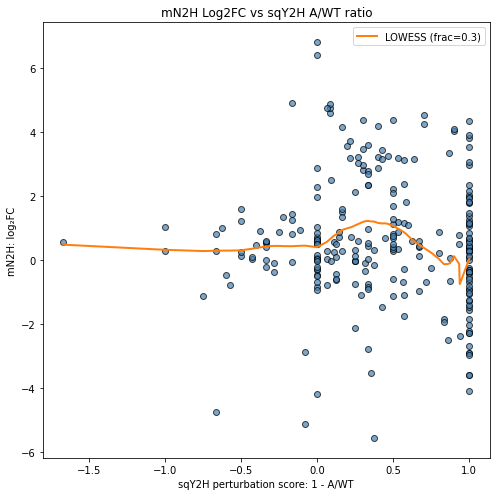

0.08432292564548984

In [ ]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    # &
    # (allele_df.WT_detected_pla == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('mN2H: log₂FC')
plt.title('mN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()
corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation


In [ ]:
retest_df.xp_mean.min(), retest_df.xp_mean.max()

(98.16666666666666, 57526813.5)

In [ ]:
allele_df.xp_mean.min(), allele_df.xp_mean.max()

(1071.3333333333333, 16198989.0)

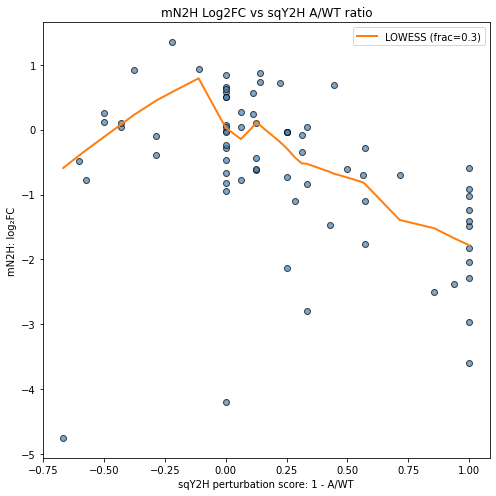

0.5258579631532031

In [ ]:
plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    ]

plot_df['1-ratio'] = 1 - plot_df['ratio']

plt.figure(figsize=(7,7))
plt.scatter(
    plot_df['1-ratio'],
    plot_df['log2fc'],
    c='steelblue', alpha=0.7, edgecolor='k'
)

from statsmodels.nonparametric.smoothers_lowess import lowess

frac = 0.3
# frac is the fraction of data used in each local regression (e.g. 0.1 = 10%)
smooth = lowess(
    endog=plot_df['log2fc'],
    exog=plot_df['1-ratio'],
    frac=frac,
    it=3,
    return_sorted=True
)
xs, ys = smooth[:,0], smooth[:,1]

plt.plot(xs, ys, linewidth=2, label=f'LOWESS (frac={frac})', color ='C1')


plt.xlabel('sqY2H perturbation score: 1 - A/WT')
plt.ylabel('mN2H: log₂FC')
plt.title('mN2H Log2FC vs sqY2H A/WT ratio')
plt.legend()
plt.tight_layout()
plt.show()

corr_df = plot_df.dropna(subset=['ratio']).replace([np.inf, -np.inf], np.nan).dropna(subset=['ratio'])
correlation = corr_df['log2fc'].corr(corr_df['ratio'], method='spearman')
correlation

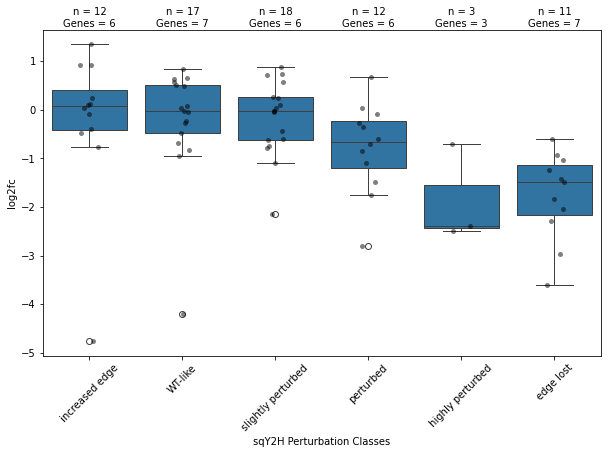

In [ ]:
# box and whiskers - perturb 2

plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]

order = ['increased edge', 'WT-like', 'slightly perturbed', 'perturbed', 'highly perturbed', 'edge lost']


plt.figure(figsize=(10, 6))
sns.boxplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order)
# plt.title('Boxplot of log2fc by perturbation_classes_2')
plt.xlabel('sqY2H Perturbation Classes')
plt.ylabel('log2fc')
plt.xticks(rotation=45)

sns.stripplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order, color='black', alpha=0.5, size=5)

for i, category in enumerate(order):
    count = plot_df_perturb[plot_df_perturb['perturbation_classes_2'] == category].shape[0]
    num_genes = plot_df_perturb[plot_df_perturb['perturbation_classes_2'] == category]['N2_orf_id'].nunique()
    plt.text(i, plt.ylim()[1] * 1.01, f'n = {count}\nGenes = {num_genes}', ha='center', va='bottom')



plt.show()



# Group by perturbation_classes_2 and N2_orf_id, then count unique N2_mut_id values
gene_variant_counts_per_bin = plot_df_perturb.groupby(['perturbation_classes_2', 'N2_orf_id'])['N2_mut_id'].nunique().reset_index()
gene_variant_counts_per_bin.columns = ['Perturbation_Class', 'N2_orf_id', 'Variant_Count']

# for perturbation_class in order:
#     print(f"\nVariants per gene in {perturbation_class} bin:")
#     bin_data = gene_variant_counts_per_bin[gene_variant_counts_per_bin['Perturbation_Class'] == perturbation_class]
#     print(bin_data)


In [ ]:
allele_df[(allele_df.N1_orf_id == 6446)

]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
131,93324.0,6446,ERGIC3,NaN,4062,PLP1,201422,9.0,B01,mN2Hapwtv2,...,False,1.352638,not_detected,1,1,0.833333,False,similar,slightly perturbed,Moderate increase
154,93367.0,6446,ERGIC3,NaN,4062,PLP1,201425,9.0,F06,mN2Hapwtv2,...,False,0.749232,not_detected,1,1,NaN,NaN,NaN,NaN,Weak increase
157,93371.0,6446,ERGIC3,NaN,4062,PLP1,201426,9.0,B07,mN2Hapwtv2,...,False,-1.935289,not_detected,1,1,0.166667,True,very highly perturbed,highly perturbed,Moderate decrease
174,93402.0,6446,ERGIC3,NaN,4062,PLP1,201423,9.0,A11,mN2Hapwtv2,...,False,-1.558826,not_detected,1,1,0.000000,True,edge lost,edge lost,Moderate decrease
179,93414.0,6446,ERGIC3,NaN,4062,PLP1,201424,9.0,E12,mN2Hapwtv2,...,False,-0.015111,not_detected,1,1,0.000000,True,edge lost,edge lost,Neutral
192,93430.0,6446,ERGIC3,NaN,4062,PLP1,201428,10.0,F02,mN2Hapwtv2,...,False,1.159952,not_detected,1,1,0.833333,False,similar,slightly perturbed,Moderate increase
201,93453.0,6446,ERGIC3,NaN,4062,PLP1,201427,10.0,E05,mN2Hapwtv2,...,False,0.820228,not_detected,1,1,NaN,NaN,NaN,NaN,Weak increase
217,93473.0,6446,ERGIC3,NaN,4062,PLP1,201429,10.0,B08,mN2Hapwtv2,...,False,0.950995,not_detected,1,1,0.666667,False,slightly perturbed,perturbed,Weak increase
223,93487.0,6446,ERGIC3,NaN,4062,PLP1,201430,10.0,H09,mN2Hapwtv2,...,False,0.436502,not_detected,1,1,0.333333,True,highly perturbed,perturbed,Neutral
229,93498.0,6446,ERGIC3,NaN,4062,PLP1,201431,10.0,C11,mN2Hapwtv2,...,False,0.820616,not_detected,1,1,1.666667,False,increased edge,increased edge,Weak increase


In [ ]:
retest_df[(retest_df.N1_orf_id == 6446)
          &
          (retest_df.variant_id == 'empty_N2')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
751,93350.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,9.0,E04,mN2Hapwtv2,...,129.0,5784.0,6564.0,8909,False,False,123.0,7085.666667,3604.333333,NaN
841,93440.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,10.0,H03,mN2Hapwtv2,...,20975.0,41489.0,36104.0,44031,False,False,15410.0,40541.333333,27975.666667,NaN
933,93532.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,11.0,G03,mN2Hapwtv2,...,1075.0,1854.0,1787.0,2008,False,False,821.0,1883.000000,1352.000000,NaN


In [ ]:
retest_df[(retest_df.retest_pla == 10)
          &
          (retest_df.variant_id == 'wt')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
821,93420.0,3731.0,PRPS1,NaN,3731.0,PRPS1,0.0,10.0,D01,mN2Hapwtv2,...,281676.0,388933.0,477480.0,484898,False,False,1.930687e+05,4.504370e+05,3.217528e+05,0.0
826,93425.0,2012.0,LHFPL5,NaN,4062.0,PLP1,0.0,10.0,A02,mN2Hapwtv2,...,1467035.0,1479672.0,1803690.0,1812655,False,False,9.881260e+05,1.698672e+06,1.343399e+06,0.0
844,93443.0,4935.0,SLC18A1,NaN,4062.0,PLP1,0.0,10.0,C04,mN2Hapwtv2,...,1133855.0,1836294.0,1749730.0,1909848,False,False,8.885870e+05,1.831957e+06,1.360272e+06,0.0
845,93444.0,4946.0,PTPRN,NaN,4062.0,PLP1,0.0,10.0,D04,mN2Hapwtv2,...,4523842.0,7228194.0,7457985.0,7669491,False,False,4.969697e+06,7.451890e+06,6.210794e+06,0.0
852,93451.0,11621.0,MTIF3,NaN,4062.0,PLP1,0.0,10.0,C05,mN2Hapwtv2,...,120858.0,237656.0,240057.0,267522,False,False,1.045370e+05,2.484117e+05,1.764743e+05,0.0
875,93474.0,12825.0,CLDN20,NaN,4062.0,PLP1,0.0,10.0,C08,mN2Hapwtv2,...,740256.0,773456.0,733521.0,748005,False,False,4.973887e+05,7.516607e+05,6.245247e+05,0.0
886,93485.0,6446.0,ERGIC3,NaN,4062.0,PLP1,0.0,10.0,F09,mN2Hapwtv2,...,302607.0,415385.0,403393.0,442708,False,False,2.403520e+05,4.204953e+05,3.304237e+05,0.0
895,93494.0,8186.0,CLEC2D,NaN,4062.0,PLP1,0.0,10.0,G10,mN2Hapwtv2,...,1963059.0,3542380.0,3336609.0,3775867,False,False,1.703578e+06,3.551619e+06,2.627598e+06,0.0
900,93499.0,13628.0,KLRC1,NaN,4062.0,PLP1,0.0,10.0,D11,mN2Hapwtv2,...,4187150.0,4625358.0,4786691.0,4147226,False,False,2.793376e+06,4.519758e+06,3.656567e+06,0.0
901,93500.0,5793.0,MS4A3,NaN,4062.0,PLP1,0.0,10.0,E11,mN2Hapwtv2,...,200643.0,233776.0,207441.0,212568,False,False,1.496733e+05,2.179283e+05,1.838008e+05,0.0


In [ ]:
retest_df[(retest_df.retest_pla == 10)
          &
          (retest_df.variant_id == 'empty_N2')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
832,93431.0,4946.0,PTPRN,NaN,0.0,NaN,0.0,10.0,G02,mN2Hapwtv2,...,1704249.0,3011019.0,3261079.0,3725548,False,False,1.738708e+06,3.332549e+06,2.535628e+06,NaN
833,93432.0,12825.0,CLDN20,NaN,0.0,NaN,0.0,10.0,H02,mN2Hapwtv2,...,939.0,1854.0,1793.0,1928,False,False,7.386667e+02,1.858333e+03,1.298500e+03,NaN
836,93435.0,11130.0,SLC35E3,NaN,0.0,NaN,0.0,10.0,C03,mN2Hapwtv2,...,619933.0,1346687.0,1127028.0,1190800,False,False,6.393420e+05,1.221505e+06,9.304235e+05,NaN
841,93440.0,6446.0,ERGIC3,NaN,0.0,NaN,0.0,10.0,H03,mN2Hapwtv2,...,20975.0,41489.0,36104.0,44031,False,False,1.541000e+04,4.054133e+04,2.797567e+04,NaN
855,93454.0,8186.0,CLEC2D,NaN,0.0,NaN,0.0,10.0,F05,mN2Hapwtv2,...,24272.0,26900.0,22829.0,30185,False,False,1.642700e+04,2.663800e+04,2.153250e+04,NaN
856,93455.0,5793.0,MS4A3,NaN,0.0,NaN,0.0,10.0,G05,mN2Hapwtv2,...,2118.0,2444.0,2628.0,3064,False,False,1.412000e+03,2.712000e+03,2.062000e+03,NaN
863,93462.0,8165.0,HAS3,NaN,0.0,NaN,0.0,10.0,F06,mN2Hapwtv2,...,19655.0,16849.0,18820.0,18740,False,False,1.357633e+04,1.813633e+04,1.585633e+04,NaN
880,93479.0,3731.0,PRPS1,NaN,0.0,NaN,0.0,10.0,H08,mN2Hapwtv2,...,2622.0,4390.0,5839.0,6005,False,False,1.977000e+03,5.411333e+03,3.694167e+03,NaN
882,93481.0,2012.0,LHFPL5,NaN,0.0,NaN,0.0,10.0,B09,mN2Hapwtv2,...,2462.0,3058.0,3310.0,3217,False,False,1.848000e+03,3.195000e+03,2.521500e+03,NaN
890,93489.0,13628.0,KLRC1,NaN,0.0,NaN,0.0,10.0,B10,mN2Hapwtv2,...,27256.0,30155.0,29897.0,28478,False,False,2.422900e+04,2.951000e+04,2.686950e+04,NaN


In [ ]:
retest_df[(retest_df.variant_id == 'SKP1_SKP2_ctrl') | (retest_df.variant_id == 'SKP1_BTRC_ctrl')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
20,92623.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,1.0,E03,mN2Hapwtv2,...,1019144.0,1559543.0,1859357.0,1722952,False,False,9.484990e+05,1.713951e+06,1.331225e+06,NaN
21,92624.0,6671.0,SKP1,NaN,9477.0,BTRC,0.0,1.0,F03,mN2Hapwtv2,...,566145.0,731556.0,671775.0,791920,False,False,4.545753e+05,7.317503e+05,5.931628e+05,NaN
78,92677.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,1.0,C10,mN2Hapwtv2,...,1065779.0,1314543.0,1687094.0,1549037,False,False,8.339955e+05,1.516891e+06,1.175443e+06,NaN
79,92678.0,6671.0,SKP1,NaN,9477.0,BTRC,0.0,1.0,D10,mN2Hapwtv2,...,677399.0,892668.0,966492.0,950976,False,False,5.770827e+05,9.367120e+05,7.568973e+05,NaN
117,92716.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,2.0,E03,mN2Hapwtv2,...,1205370.0,1655797.0,1879405.0,1881621,False,False,1.324373e+06,1.805608e+06,1.564990e+06,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012,94611.0,6671.0,SKP1,NaN,9477.0,BTRC,0.0,22.0,D10,mN2Hapwtv2,...,133850.0,NaN,244411.0,225616,False,False,1.230743e+05,2.350135e+05,1.790439e+05,NaN
2052,94651.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,23.0,E03,mN2Hapwtv2,...,244926.0,225972.0,197647.0,288688,False,False,2.410827e+05,2.374357e+05,2.392592e+05,NaN
2053,94652.0,6671.0,SKP1,NaN,9477.0,BTRC,0.0,23.0,F03,mN2Hapwtv2,...,84680.0,166068.0,171054.0,201214,False,False,9.624967e+04,1.794453e+05,1.378475e+05,NaN
2087,94686.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,23.0,C10,mN2Hapwtv2,...,201773.0,136822.0,285206.0,248181,False,False,2.024630e+05,2.234030e+05,2.129330e+05,NaN


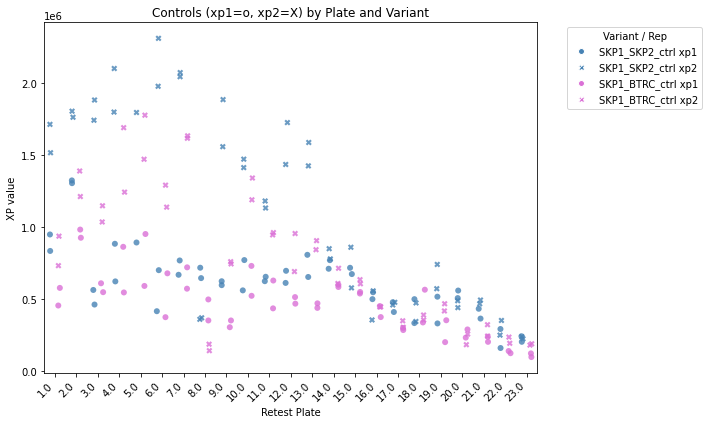

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['SKP1_SKP2_ctrl','SKP1_BTRC_ctrl']
df_ctrl = retest_df[retest_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    'SKP1_SKP2_ctrl':'steelblue',
    'SKP1_BTRC_ctrl':'orchid'
    # 'empty_N1':'green',
    # 'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp1',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    marker='o',
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 4) xp2 as crosses, same dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp2',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    marker='X',
    size=6,
    alpha=0.8,
    legend=False
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls (xp1=o, xp2=X) by Plate and Variant')
plt.xticks(rotation=45, ha='right')

# 6) Manual legend
handles = []
for var, color in var_palette.items():
    handles.append(Line2D([0],[0], marker='o', color='w',
                          label=f'{var} xp1',
                          markerfacecolor=color, markersize=6))
    handles.append(Line2D([0],[0], marker='X', color='w',
                          label=f'{var} xp2',
                          markerfacecolor=color, markersize=6))
plt.legend(handles, [h.get_label() for h in handles],
           bbox_to_anchor=(1.05,1), loc='upper left', title='Variant / Rep')

plt.tight_layout()
plt.show()


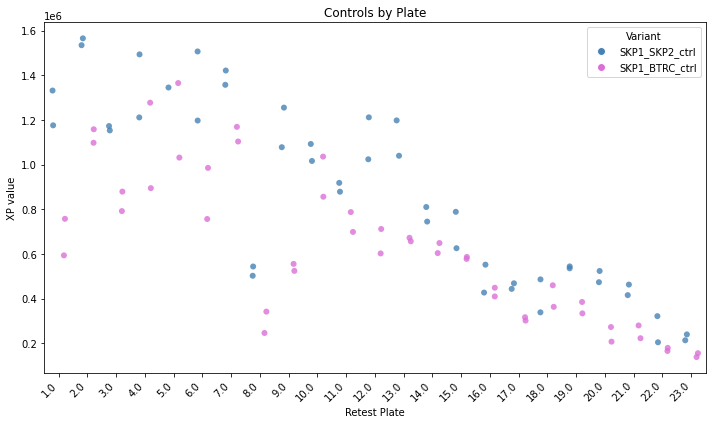

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['SKP1_SKP2_ctrl','SKP1_BTRC_ctrl']
df_ctrl = retest_df[retest_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    'SKP1_SKP2_ctrl':'steelblue',
    'SKP1_BTRC_ctrl':'orchid'
    # 'empty_N1':'green',
    # 'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp_mean',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls by Plate')
plt.xticks(rotation=45, ha='right')

# 6) Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='SKP1_SKP2_ctrl', markerfacecolor='steelblue', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='SKP1_BTRC_ctrl', markerfacecolor='orchid', markersize=8)
]
plt.legend(handles=legend_elements, title='Variant')


plt.tight_layout()
plt.show()


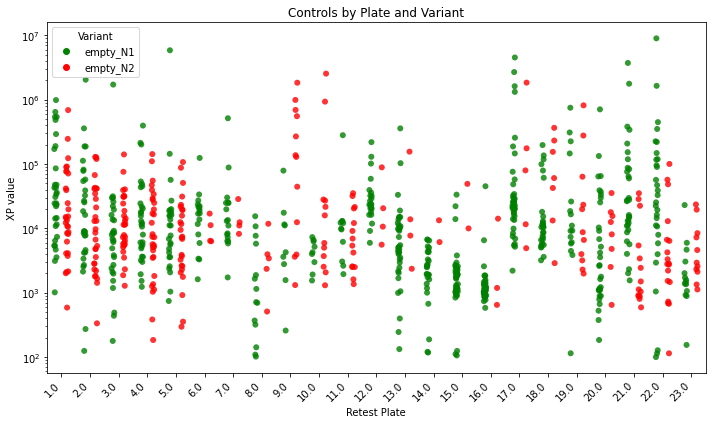

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1) Subset & prep
ctrl_ids = ['empty_N1', 'empty_N2']
df_ctrl = retest_df[retest_df.variant_id.isin(ctrl_ids)].copy()
df_ctrl['plate_str'] = df_ctrl['retest_pla'].astype(str)

# 2) Color mapping
var_palette = {
    # 'SKP1_SKP2_ctrl':'steelblue',
    # 'NCBP1_NCBP2_ctrl':'orchid'
    'empty_N1':'green',
    'empty_N2':'red'
}

plt.figure(figsize=(10,6))

# 3) xp1 as circles, variant dodge
sns.stripplot(
    data=df_ctrl,
    x='plate_str', y='xp_mean',
    hue='variant_id',
    dodge=True,
    palette=var_palette,
    size=6,
    alpha=0.8,
    legend=False   # we'll do a manual legend
)

# 5) Tidy axes
plt.xlabel('Retest Plate')
plt.ylabel('XP value')
plt.title('Controls by Plate and Variant')
plt.xticks(rotation=45, ha='right')

# 6) Manual legend
# 6) Custom legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='empty_N1', markerfacecolor='green', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='empty_N2', markerfacecolor='red', markersize=8)
]
plt.legend(handles=legend_elements, title='Variant')
plt.yscale('log')

plt.tight_layout()
plt.show()


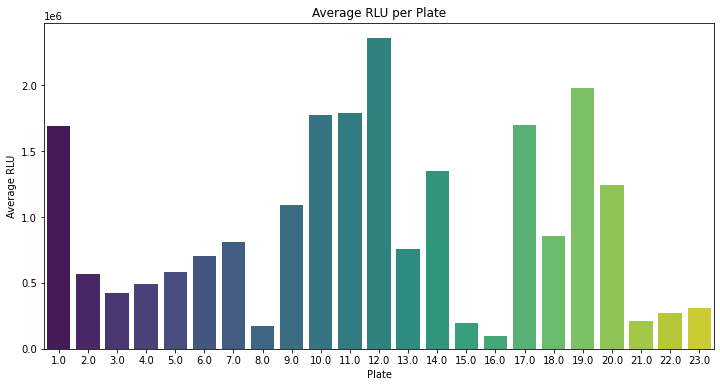

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average nlr per plate
avg_nlr_per_plate = retest_df.groupby('retest_pla')['xp_mean'].mean().reset_index()

# Set up the plot
plt.figure(figsize=(12, 6))

# Plot the average nlr per plate
sns.barplot(data=avg_nlr_per_plate, x='retest_pla', y='xp_mean', palette='viridis')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('Average RLU')
plt.title('Average RLU per Plate')

# Show the plot
plt.show()

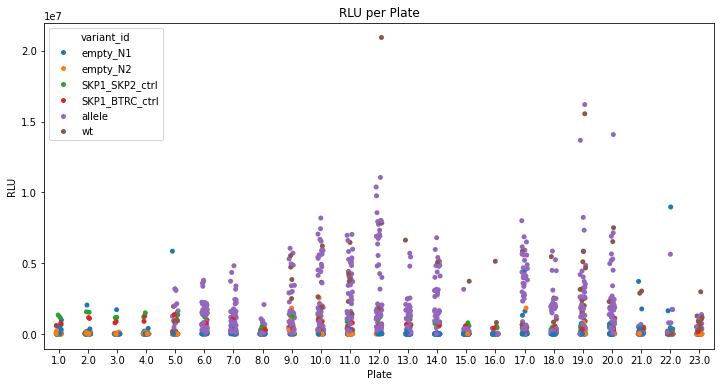

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plot
plt.figure(figsize=(12, 6))

apwt_plot = retest_df[(retest_df.variant_id != 'RRS')
                    & (retest_df.variant_id != 'PRS')]

# Plot the swarm plot
sns.stripplot(data=apwt_plot, x='retest_pla', y='xp_mean', hue='variant_id')

# y axis log2
# plt.yscale('log')

# Add labels and title
plt.xlabel('Plate')
plt.ylabel('RLU')
plt.title('RLU per Plate')

# Show the plot
plt.show()

In [ ]:
retest_df[retest_df.retest_pla == 8]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
660,93259.0,7233.0,STX5,NaN,7652.0,STXBP1,0.0,8.0,A01,mN2Hapwtv2,...,116559.0,28957.0,38075.0,33992,False,False,92424.000000,33674.666667,63049.333333,0.000000
661,93260.0,7233.0,STX5,NaN,7652.0,STXBP1,1837.0,8.0,B01,mN2Hapwtv2,...,1073761.0,381871.0,471899.0,467994,False,False,930281.000000,440588.000000,685434.500000,1.318118
662,93261.0,7675.0,NMNAT1,NaN,7675.0,NMNAT1,202590.0,8.0,C01,mN2Hapwtv2,...,136251.0,44449.0,53088.0,55452,False,False,103581.000000,50996.333333,77288.666667,0.217008
663,93262.0,14387.0,CENPP,NaN,0.0,NaN,0.0,8.0,D01,mN2Hapwtv2,...,4998.0,1412.0,1646.0,1510,False,False,5289.500000,1522.666667,3406.083333,NaN
664,93263.0,0.0,NaN,NaN,7652.0,STXBP1,13919.0,8.0,E01,mN2Hapwtv2,...,104.0,92.0,135.0,104,False,False,92.000000,110.333333,101.166667,-0.560023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
719,93318.0,7675.0,NMNAT1,NaN,7675.0,NMNAT1,0.0,8.0,D08,mN2Hapwtv2,...,146665.0,30891.0,57914.0,47200,False,False,172902.000000,45335.000000,109118.500000,0.000000
720,93319.0,0.0,NaN,NaN,7652.0,STXBP1,0.0,8.0,E08,mN2Hapwtv2,...,282.0,233.0,264.0,227,False,False,493.333333,241.333333,367.333333,0.000000
721,93320.0,199.0,SYTL4,NaN,7652.0,STXBP1,1837.0,8.0,F08,mN2Hapwtv2,...,82039.0,37449.0,46487.0,52836,False,False,133208.500000,45590.666667,89399.583333,1.318118
722,93321.0,6671.0,SKP1,NaN,4656.0,SKP2,0.0,8.0,C10,mN2Hapwtv2,...,748816.0,341518.0,371967.0,362616,False,False,645062.666667,358700.333333,501881.500000,NaN


In [ ]:
retest_df[retest_df.retest_pla == 9]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
724,93323.0,0.0,NaN,NaN,4062.0,PLP1,201426.0,9.0,A01,mN2Hapwtv2,...,60020.0,96217.0,91986.0,113452,False,False,5.676300e+04,1.005517e+05,7.865733e+04,1.453521
725,93324.0,6446.0,ERGIC3,NaN,4062.0,PLP1,201422.0,9.0,B01,mN2Hapwtv2,...,722038.0,956029.0,968211.0,1124271,False,False,5.281043e+05,1.016170e+06,7.721373e+05,0.184515
726,93325.0,0.0,NaN,NaN,4062.0,PLP1,201425.0,9.0,C01,mN2Hapwtv2,...,2622.0,5520.0,5532.0,5385,False,False,1.721333e+03,5.479000e+03,3.600167e+03,0.114104
727,93326.0,2012.0,LHFPL5,NaN,4062.0,PLP1,0.0,9.0,E01,mN2Hapwtv2,...,370500.0,468012.0,521463.0,563357,False,False,3.509650e+05,5.176107e+05,4.342878e+05,0.000000
728,93327.0,8186.0,CLEC2D,NaN,4062.0,PLP1,201426.0,9.0,F01,mN2Hapwtv2,...,2382729.0,3450068.0,3829293.0,3902159,False,False,2.069220e+06,3.727173e+06,2.898196e+06,1.453521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
813,93412.0,11621.0,MTIF3,NaN,0.0,NaN,0.0,9.0,C12,mN2Hapwtv2,...,102253.0,170262.0,179951.0,205598,False,False,8.824400e+04,1.852703e+05,1.367572e+05,NaN
814,93413.0,8165.0,HAS3,NaN,4062.0,PLP1,0.0,9.0,D12,mN2Hapwtv2,...,422599.0,402920.0,469105.0,530452,False,False,3.847415e+05,4.674923e+05,4.261169e+05,0.000000
815,93414.0,6446.0,ERGIC3,NaN,4062.0,PLP1,201424.0,9.0,E12,mN2Hapwtv2,...,219819.0,370991.0,401968.0,493439,False,False,1.952430e+05,4.221327e+05,3.086878e+05,-0.248398
816,93415.0,11130.0,SLC35E3,NaN,4062.0,PLP1,201423.0,9.0,F12,mN2Hapwtv2,...,441192.0,852659.0,827502.0,1002203,False,False,4.227895e+05,8.941213e+05,6.584554e+05,-1.032567


In [ ]:
retest_df[retest_df.N2_orf_id == 281]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
1100,93699.0,0.0,NaN,NaN,281.0,MVK,200099.0,13.0,A01,mN2Hapwtv2,...,1996.0,3696.0,4120.0,3531,False,False,2.069333e+03,3.782333e+03,2.925833e+03,-0.669979
1101,93700.0,0.0,NaN,NaN,281.0,MVK,10.0,13.0,B01,mN2Hapwtv2,...,3506.0,4924.0,6760.0,5802,False,False,3.606333e+03,5.828667e+03,4.717500e+03,-0.462517
1102,93701.0,0.0,NaN,NaN,281.0,MVK,23.0,13.0,C01,mN2Hapwtv2,...,1953.0,184.0,166.0,209,False,False,1.907667e+03,1.863333e+02,1.047000e+03,-1.116282
1103,93702.0,281.0,MVK,NaN,281.0,MVK,12.0,13.0,D01,mN2Hapwtv2,...,1351108.0,1882463.0,1953627.0,2247012,False,False,1.417301e+06,2.027701e+06,1.722501e+06,-0.127977
1106,93705.0,281.0,MVK,NaN,281.0,MVK,7.0,13.0,G01,mN2Hapwtv2,...,1195202.0,2166256.0,2205106.0,1996996,False,False,1.131733e+06,2.122786e+06,1.627259e+06,-0.506582
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1186,93785.0,0.0,NaN,NaN,281.0,MVK,27.0,13.0,H11,mN2Hapwtv2,...,5244.0,14104.0,15627.0,16529,False,False,4.095333e+03,1.542000e+04,9.757667e+03,-0.146883
1187,93786.0,281.0,MVK,NaN,281.0,MVK,13.0,13.0,A12,mN2Hapwtv2,...,786854.0,1293697.0,1381760.0,1384910,False,False,6.008103e+05,1.353456e+06,9.771330e+05,-0.104794
1188,93787.0,281.0,MVK,NaN,281.0,MVK,1.0,13.0,B12,mN2Hapwtv2,...,1187951.0,2021759.0,2435173.0,2278843,False,False,1.127959e+06,2.245258e+06,1.686608e+06,-0.129164
1191,93790.0,281.0,MVK,NaN,281.0,MVK,14.0,13.0,E12,mN2Hapwtv2,...,1249887.0,1579935.0,1969567.0,1405731,False,False,8.919337e+05,1.651744e+06,1.271839e+06,-0.054612


In [ ]:
for orf, df in df_wt.groupby('N2_orf_id'):
    if df.retest_pla.nunique() > 1:
        print(orf)

        print()

2920.0

4062.0

7652.0



In [ ]:
for orf, df in retest_df.groupby('N2_orf_id'):
    n_pla = df.retest_pla.nunique()
    print(orf, n_pla)

0.0 23
19.0 1
88.0 1
97.0 1
231.0 1
248.0 1
280.0 1
281.0 1
472.0 1
510.0 1
636.0 1
645.0 1
647.0 1
798.0 1
858.0 1
1050.0 1
1063.0 1
1149.0 1
1177.0 1
1228.0 1
1235.0 1
1256.0 1
1444.0 1
1668.0 1
1683.0 1
1915.0 1
2022.0 1
2370.0 1
2388.0 1
2391.0 1
2446.0 1
2450.0 1
2455.0 1
2492.0 1
2654.0 1
2692.0 1
2713.0 1
2754.0 1
2767.0 1
2920.0 2
3011.0 1
3086.0 1
3129.0 1
3156.0 2
3171.0 1
3180.0 1
3291.0 1
3370.0 1
3375.0 1
3422.0 1
3438.0 1
3568.0 1
3683.0 1
3726.0 1
3731.0 1
3756.0 1
3769.0 1
3774.0 1
3828.0 1
3837.0 1
3926.0 1
3944.0 1
3971.0 2
4004.0 1
4056.0 1
4062.0 3
4284.0 1
4345.0 2
4447.0 1
4519.0 1
4538.0 1
4568.0 1
4596.0 1
4656.0 23
4687.0 1
4692.0 1
4722.0 1
4723.0 1
4735.0 1
4758.0 1
4782.0 1
4849.0 1
4865.0 1
4870.0 1
4910.0 1
4920.0 1
4956.0 1
5001.0 1
5046.0 1
5066.0 1
5174.0 1
5222.0 1
5271.0 1
5424.0 1
5441.0 1
5442.0 1
5546.0 1
5588.0 1
5598.0 1
5664.0 1
5712.0 1
5723.0 1
5772.0 1
5808.0 1
5887.0 1
5892.0 1
5929.0 1
5933.0 1
5946.0 1
5989.0 1
6034.0 1
6072.0 1
6173.0 1
6

In [ ]:
retest_df[(retest_df.N2_orf_id == 281)
          &
          (retest_df.retest_pla == 13)]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,xp_mean,log10fc_empty_N1
1100,93699.0,0.0,NaN,NaN,281.0,MVK,200099.0,13.0,A01,mN2Hapwtv2,...,1996.0,3696.0,4120.0,3531,False,False,2.069333e+03,3.782333e+03,2.925833e+03,-0.669979
1101,93700.0,0.0,NaN,NaN,281.0,MVK,10.0,13.0,B01,mN2Hapwtv2,...,3506.0,4924.0,6760.0,5802,False,False,3.606333e+03,5.828667e+03,4.717500e+03,-0.462517
1102,93701.0,0.0,NaN,NaN,281.0,MVK,23.0,13.0,C01,mN2Hapwtv2,...,1953.0,184.0,166.0,209,False,False,1.907667e+03,1.863333e+02,1.047000e+03,-1.116282
1103,93702.0,281.0,MVK,NaN,281.0,MVK,12.0,13.0,D01,mN2Hapwtv2,...,1351108.0,1882463.0,1953627.0,2247012,False,False,1.417301e+06,2.027701e+06,1.722501e+06,-0.127977
1106,93705.0,281.0,MVK,NaN,281.0,MVK,7.0,13.0,G01,mN2Hapwtv2,...,1195202.0,2166256.0,2205106.0,1996996,False,False,1.131733e+06,2.122786e+06,1.627259e+06,-0.506582
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1186,93785.0,0.0,NaN,NaN,281.0,MVK,27.0,13.0,H11,mN2Hapwtv2,...,5244.0,14104.0,15627.0,16529,False,False,4.095333e+03,1.542000e+04,9.757667e+03,-0.146883
1187,93786.0,281.0,MVK,NaN,281.0,MVK,13.0,13.0,A12,mN2Hapwtv2,...,786854.0,1293697.0,1381760.0,1384910,False,False,6.008103e+05,1.353456e+06,9.771330e+05,-0.104794
1188,93787.0,281.0,MVK,NaN,281.0,MVK,1.0,13.0,B12,mN2Hapwtv2,...,1187951.0,2021759.0,2435173.0,2278843,False,False,1.127959e+06,2.245258e+06,1.686608e+06,-0.129164
1191,93790.0,281.0,MVK,NaN,281.0,MVK,14.0,13.0,E12,mN2Hapwtv2,...,1249887.0,1579935.0,1969567.0,1405731,False,False,8.919337e+05,1.651744e+06,1.271839e+06,-0.054612


19.0
88.0
97.0
231.0
248.0
280.0
281.0
	 13.0


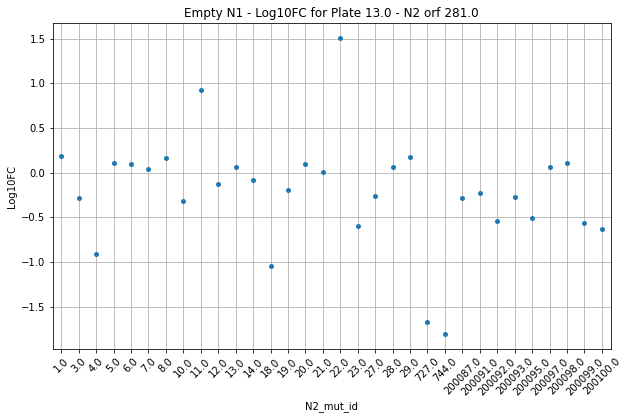

472.0
510.0
636.0
645.0
647.0
798.0
858.0
1050.0
1063.0
	 23.0


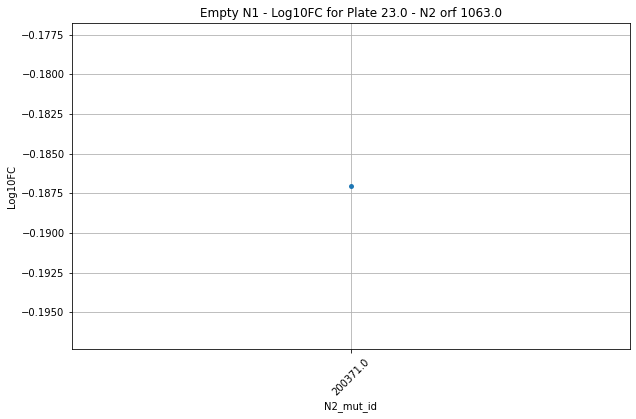

1149.0
1177.0
1228.0
1235.0
1256.0
	 21.0


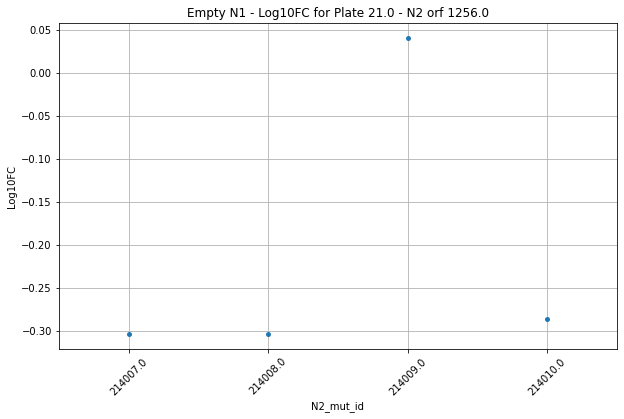

1444.0
1668.0
	 21.0


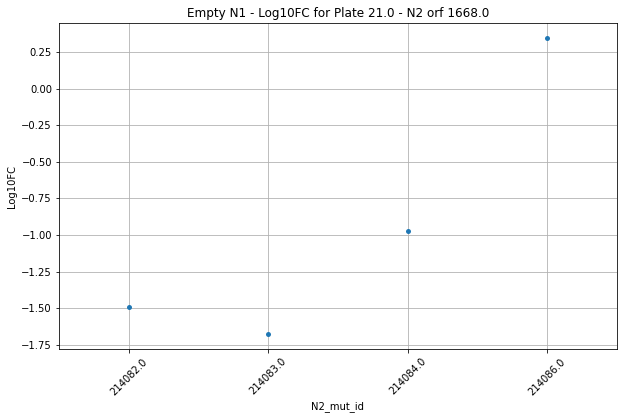

1683.0
1915.0
2022.0
2370.0
2388.0
2391.0
2446.0
2450.0
2455.0
	 21.0


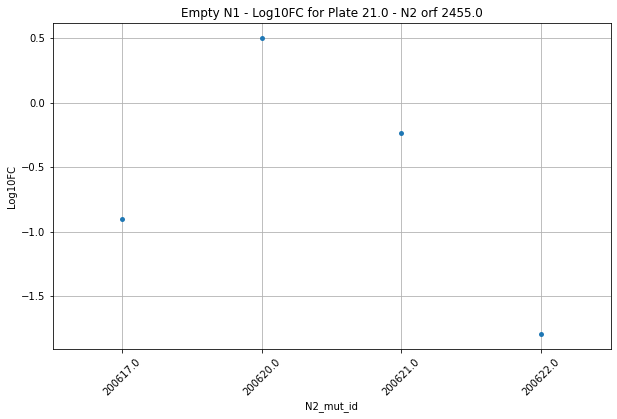

2492.0
2654.0
	 12.0


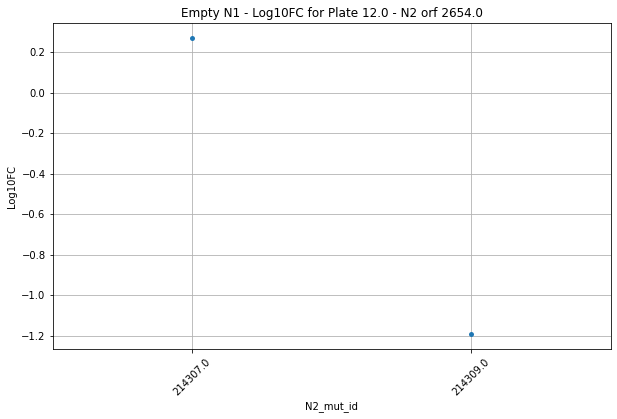

2692.0
2713.0
	 15.0


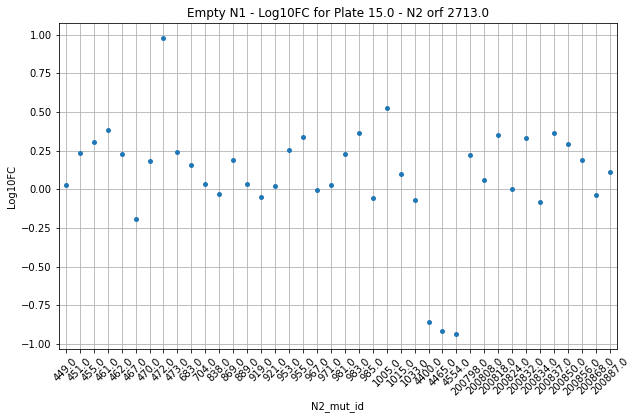

2754.0
2767.0
	 18.0


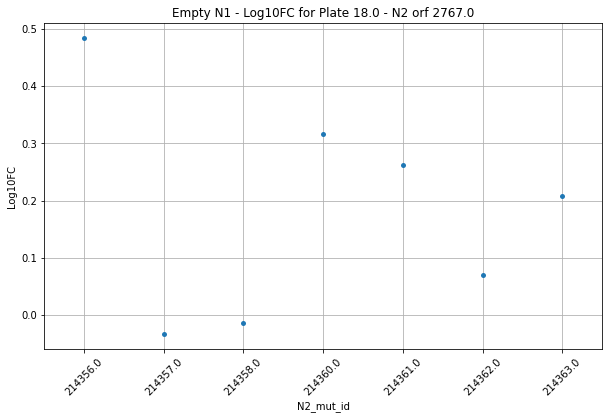

2920.0
	 12.0


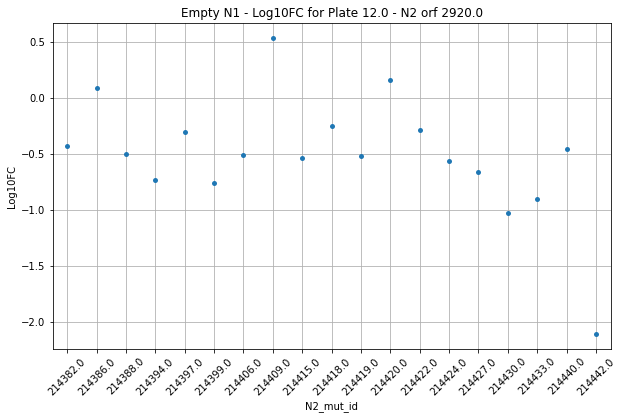

	 13.0


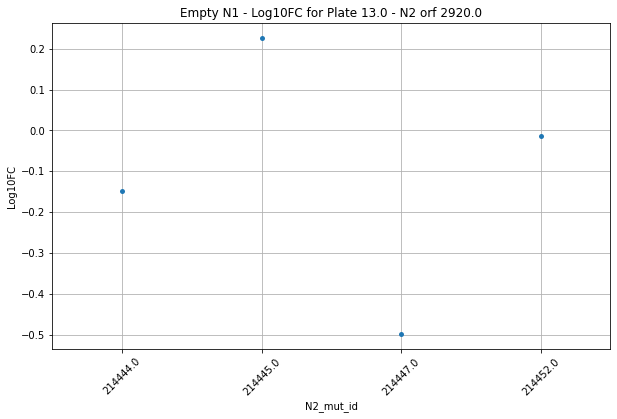

3011.0
3086.0
	 22.0


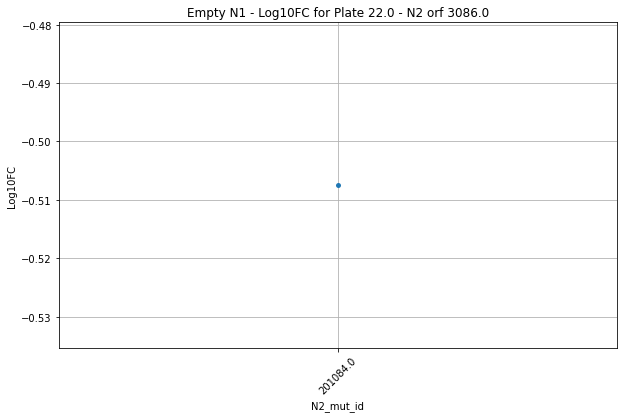

3129.0
3156.0
3171.0
3180.0
	 17.0


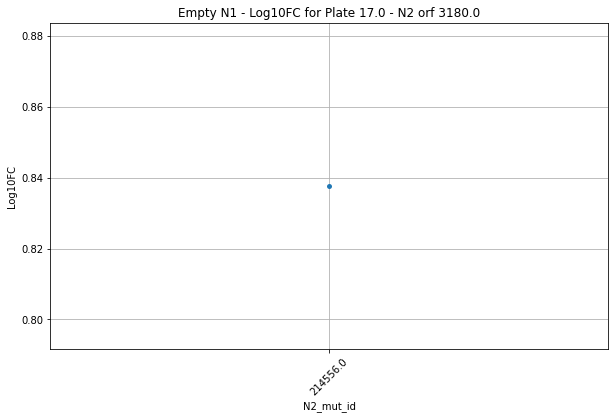

3291.0
3370.0
3375.0
3422.0
3438.0
	 23.0


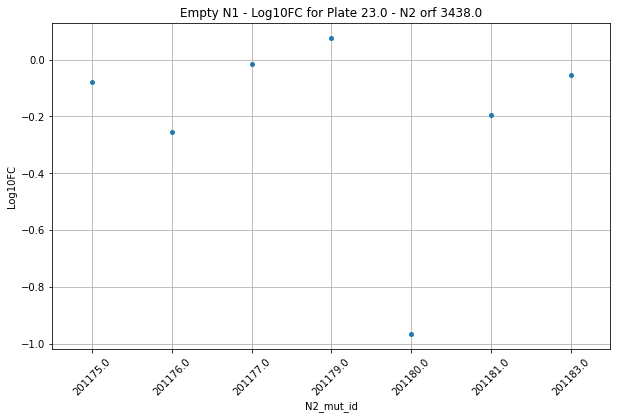

3568.0
3683.0
3726.0
3731.0
	 10.0


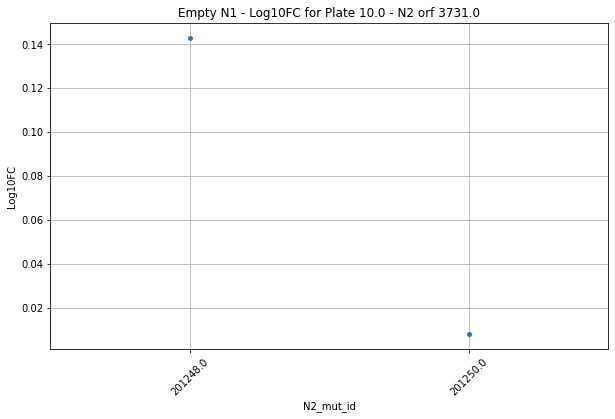

3756.0
	 22.0


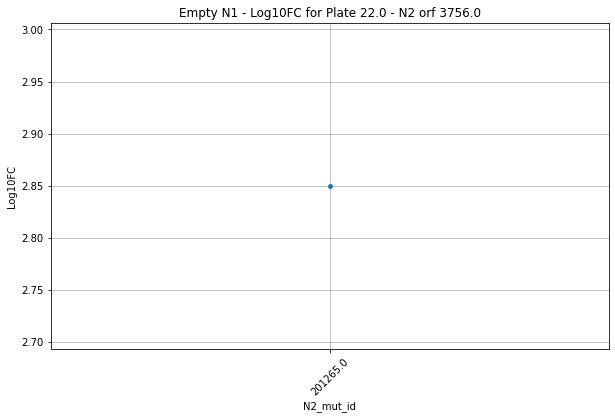

3769.0
3774.0
3828.0
3837.0
3926.0
3944.0
3971.0
4004.0
	 23.0


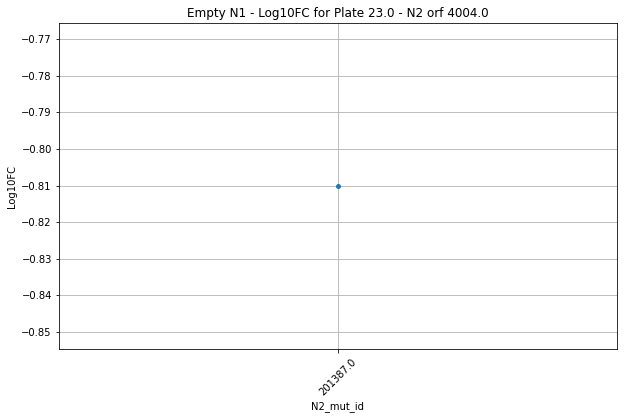

4056.0
4062.0
	 9.0


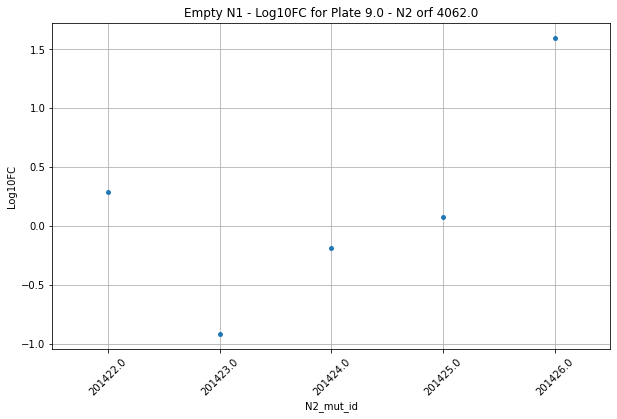

	 10.0


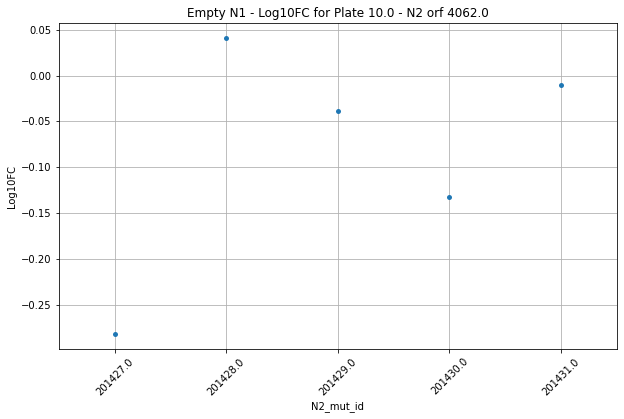

	 11.0


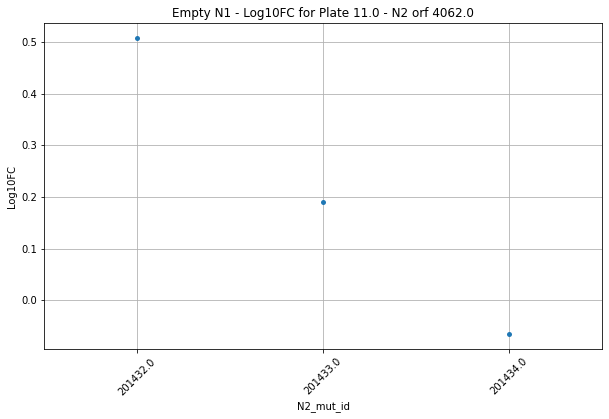

4284.0
4345.0
4447.0
4519.0
4538.0
4568.0
4596.0
4656.0
4687.0
4692.0
	 21.0


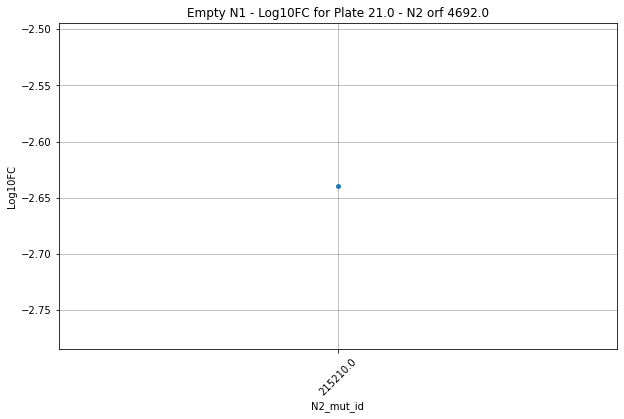

4722.0
4723.0
	 14.0


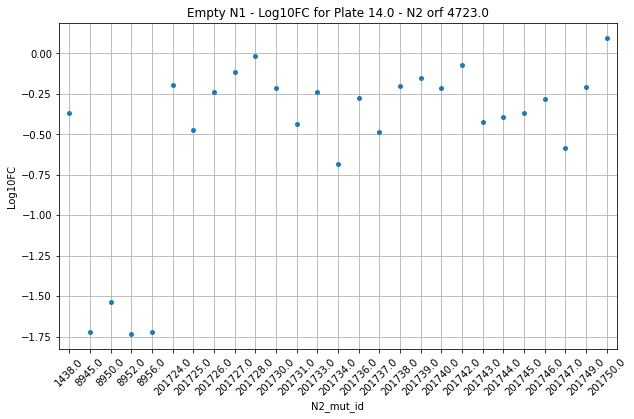

4735.0
4758.0
4782.0
4849.0
4865.0
4870.0
	 18.0


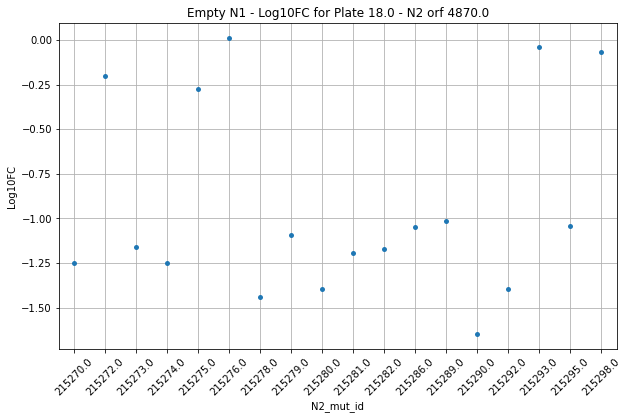

4910.0
	 21.0


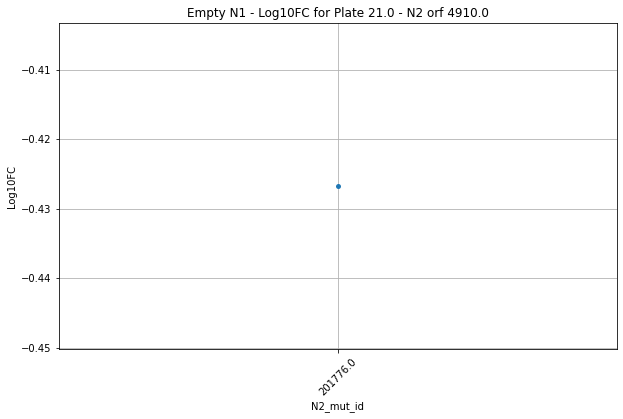

4920.0
4956.0
5001.0
5046.0
5066.0
	 22.0


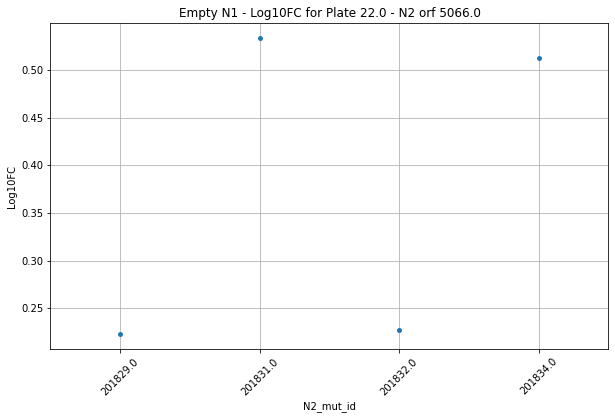

5174.0
5222.0
5271.0
5424.0
	 18.0


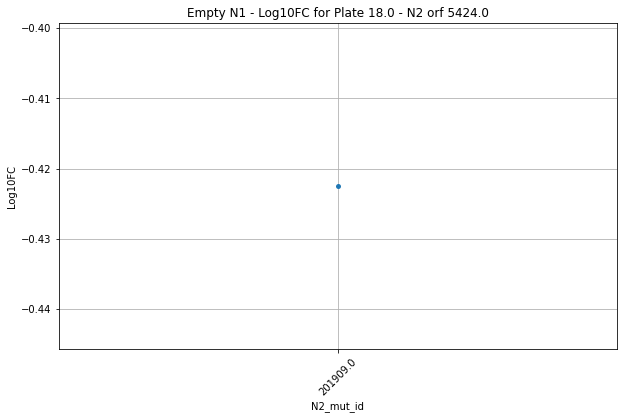

5441.0
	 20.0


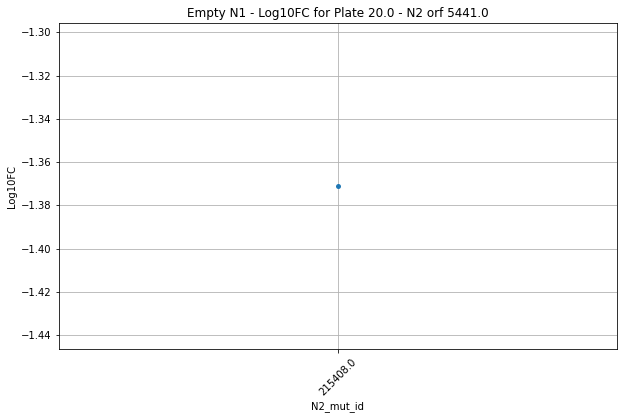

5442.0
	 17.0


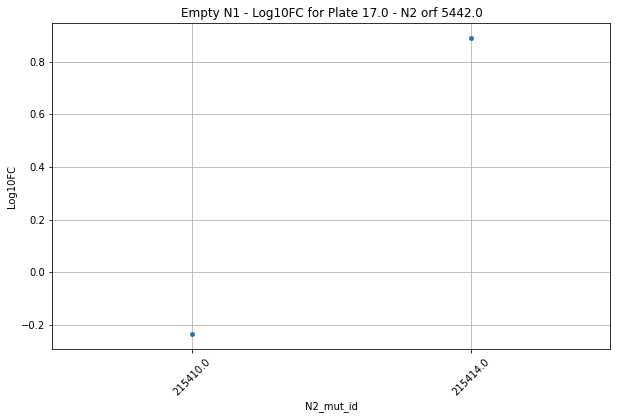

5546.0
5588.0
5598.0
5664.0
5712.0
	 22.0


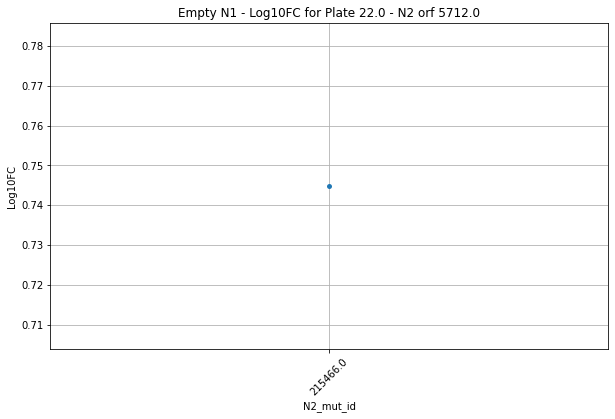

5723.0
	 20.0


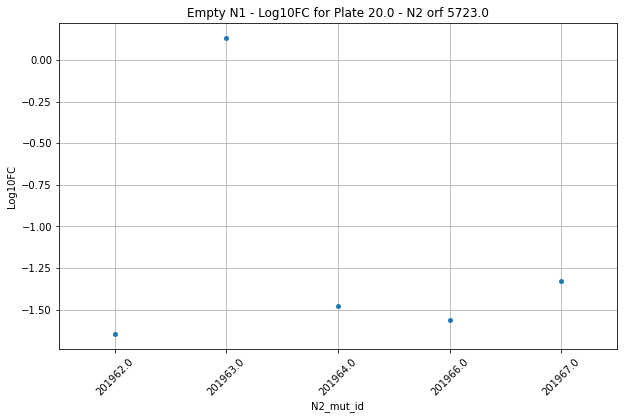

5772.0
	 16.0


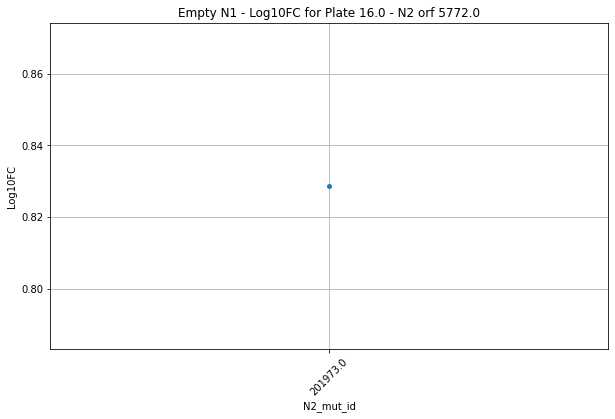

5808.0
5887.0
5892.0
5929.0
5933.0
	 22.0


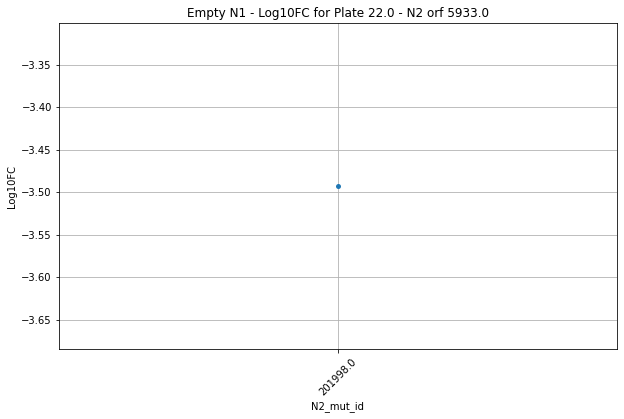

5946.0
5989.0
6034.0
6072.0
6173.0
6535.0
6601.0
6612.0
6773.0
6783.0
6811.0
6867.0
6983.0
	 21.0


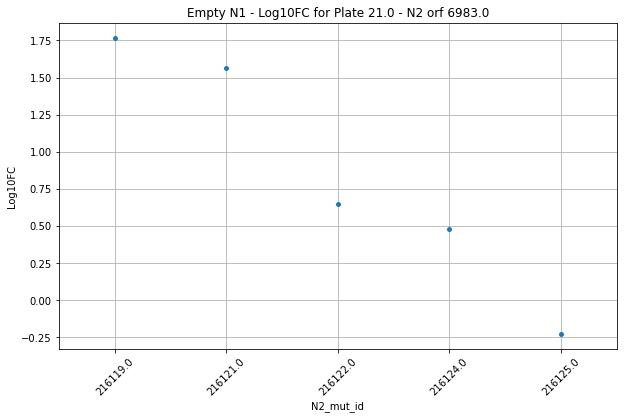

7058.0
7100.0
7182.0
7186.0
7264.0
7272.0
7273.0
7323.0
	 19.0


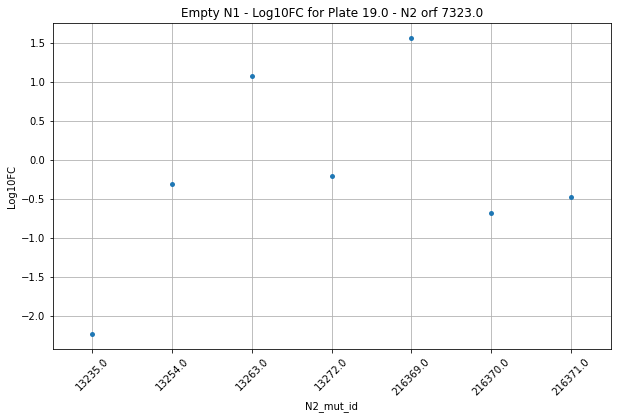

7536.0
7652.0
	 6.0


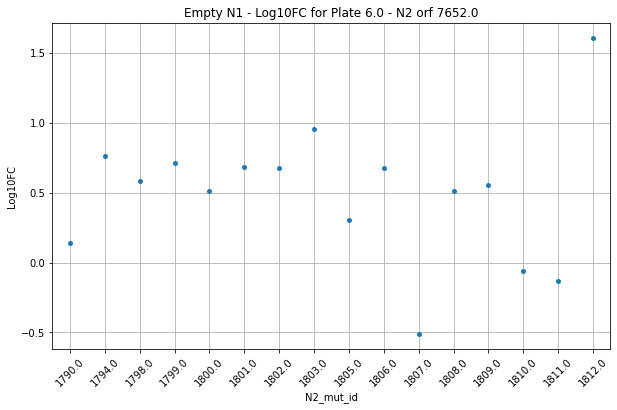

	 7.0


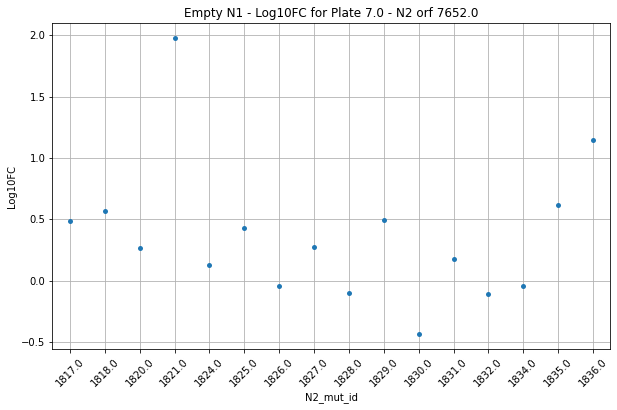

	 8.0


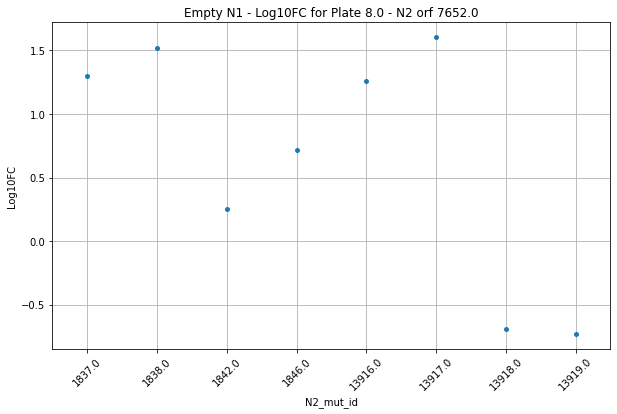

7666.0
7675.0
	 8.0


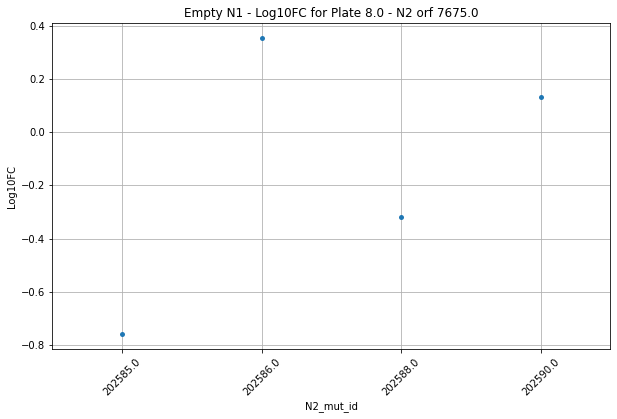

7699.0
7773.0
7886.0
7941.0
8010.0
8127.0
8186.0
8189.0
8199.0
8208.0
8297.0
8316.0
8327.0
8366.0
8578.0
8604.0
8703.0
8732.0
8763.0
8764.0
8768.0
8921.0
9307.0
9395.0
9477.0
9594.0
9618.0
9634.0
9673.0
9706.0
9726.0
	 19.0


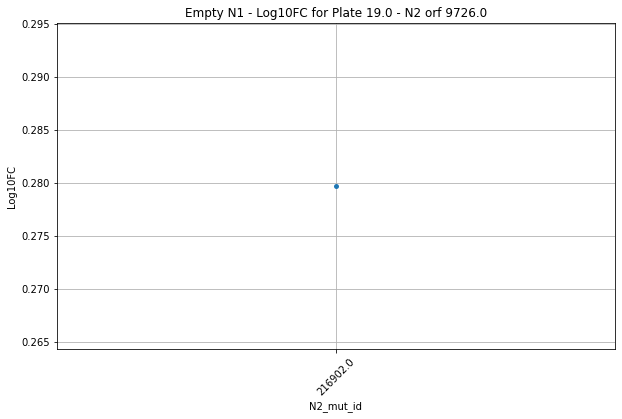

9750.0
9866.0
	 9.0


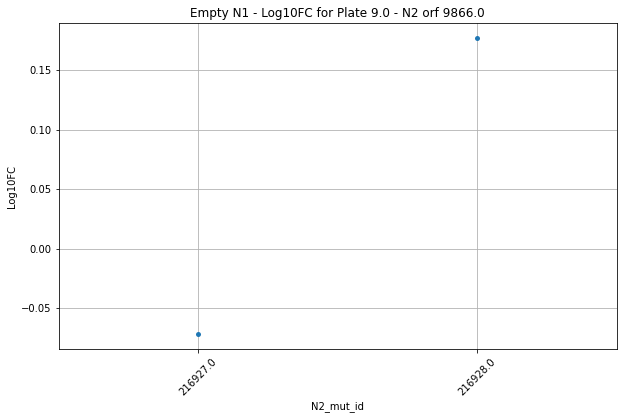

9905.0
	 21.0


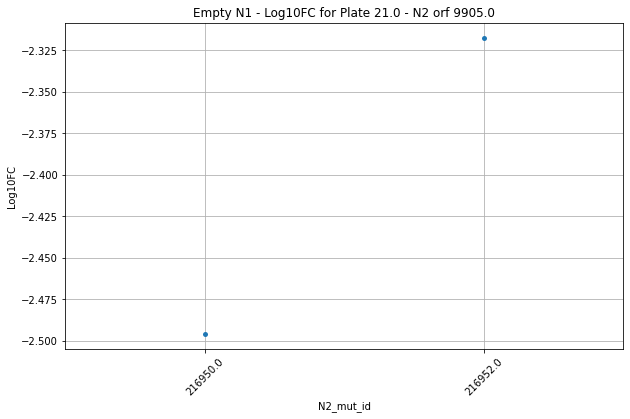

9931.0
9970.0
	 15.0


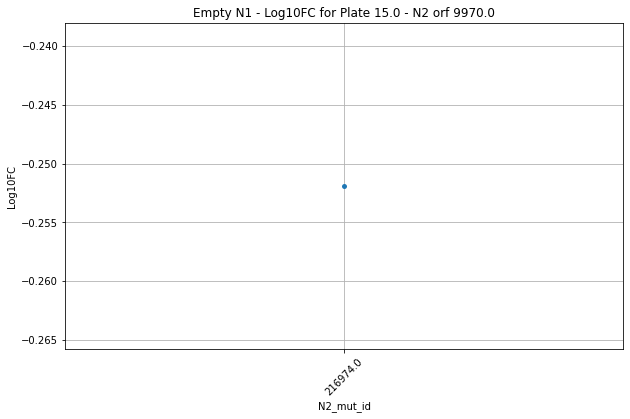

9994.0
10130.0
10233.0
11305.0
	 22.0


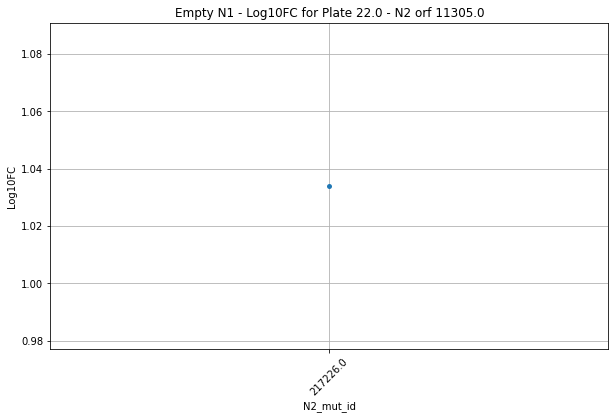

11374.0
	 22.0


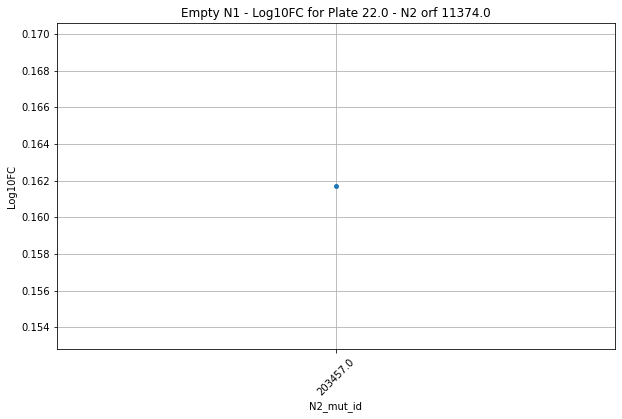

11907.0
	 22.0


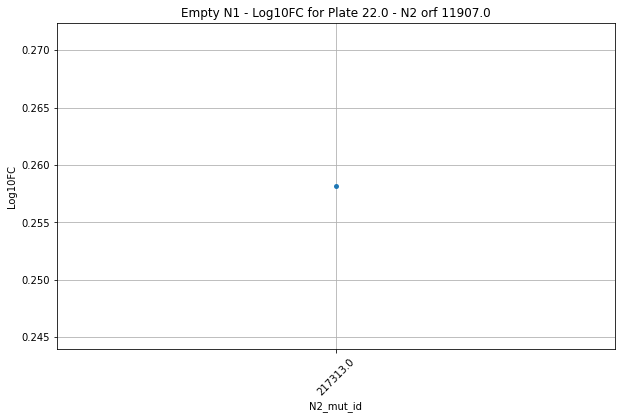

13571.0
13592.0
	 23.0


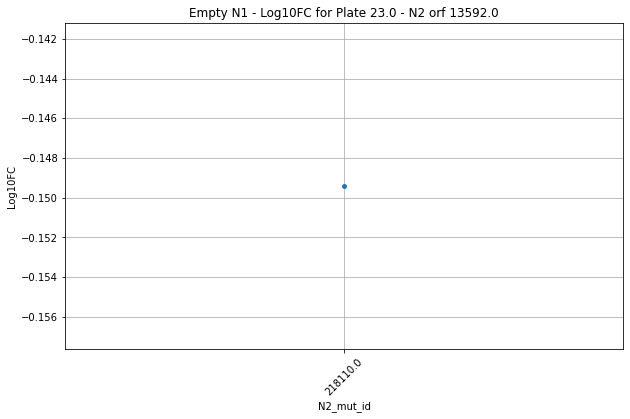

13939.0
	 19.0


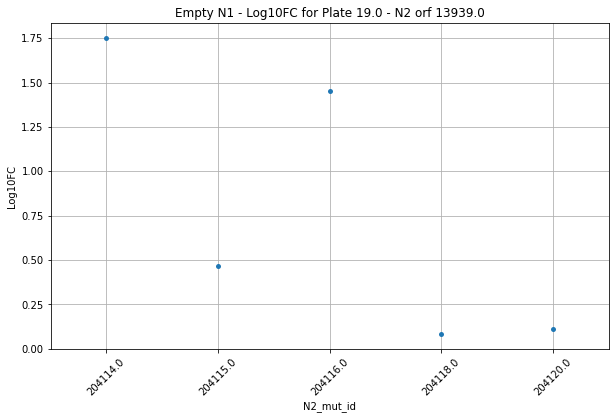

14221.0
	 20.0


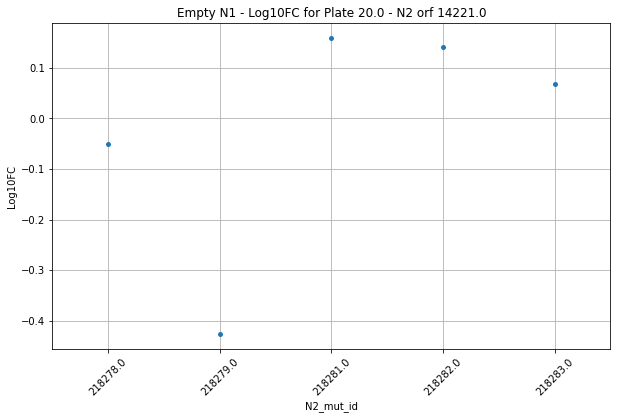

14468.0
	 22.0


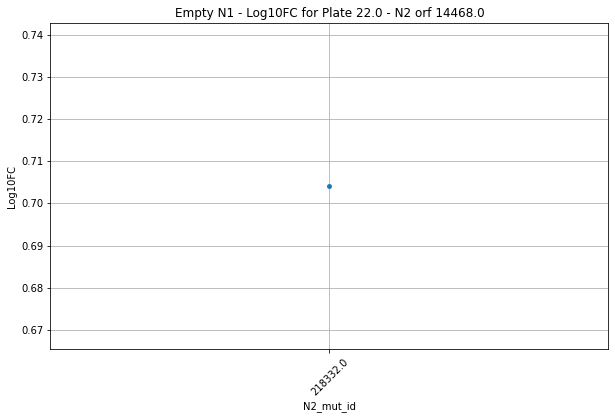

14966.0
	 11.0


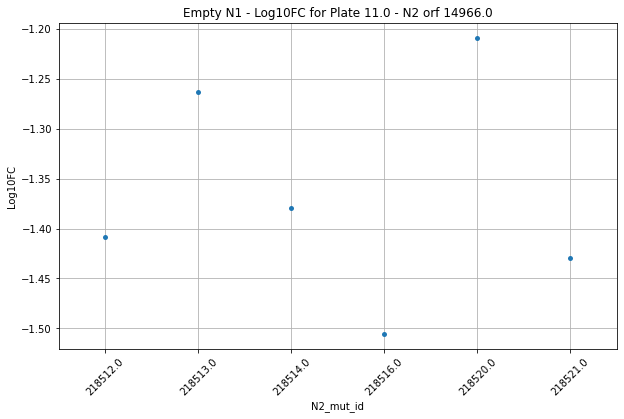

54175.0
	 22.0


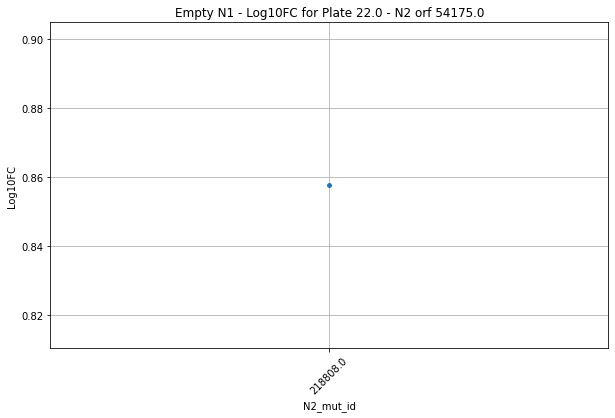

54914.0
	 22.0


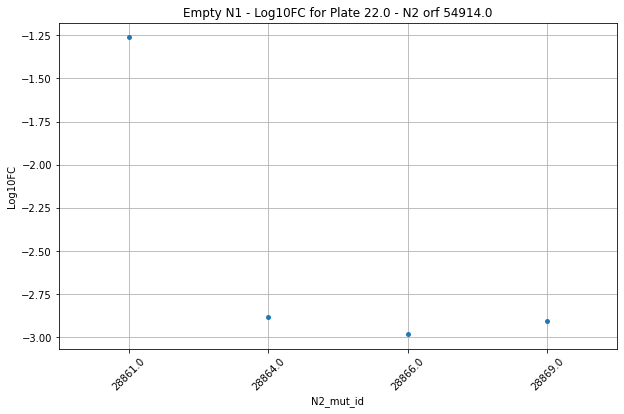

55246.0
	 20.0


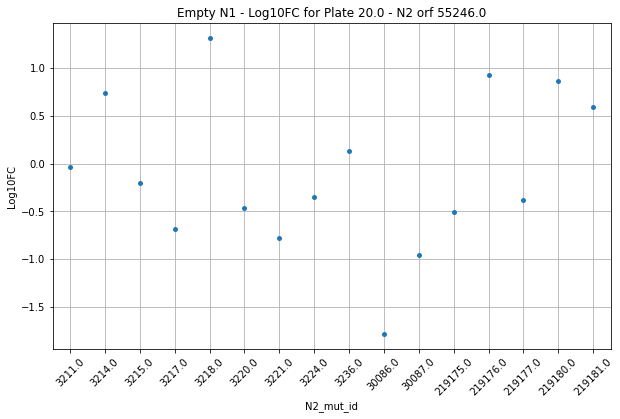

55834.0
	 21.0


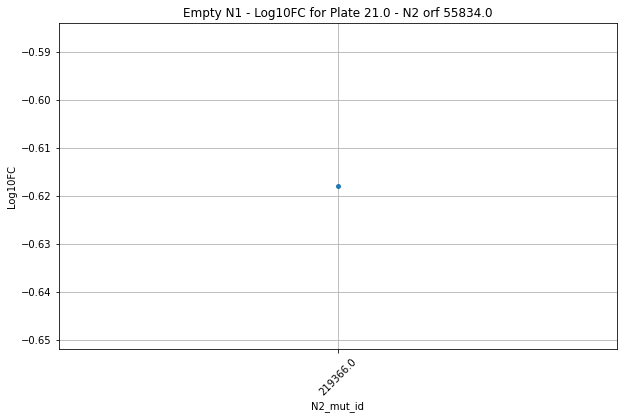

55855.0
70500.0
	 22.0


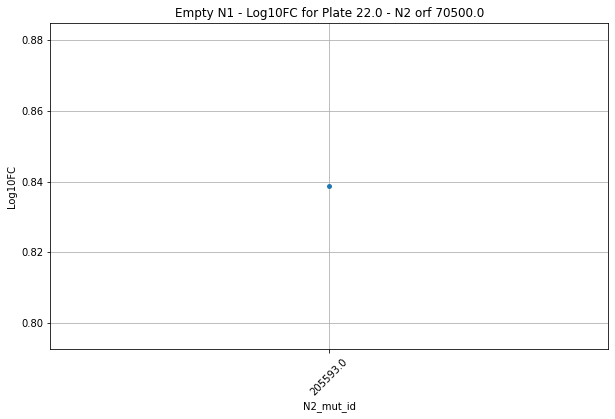

71592.0
	 21.0


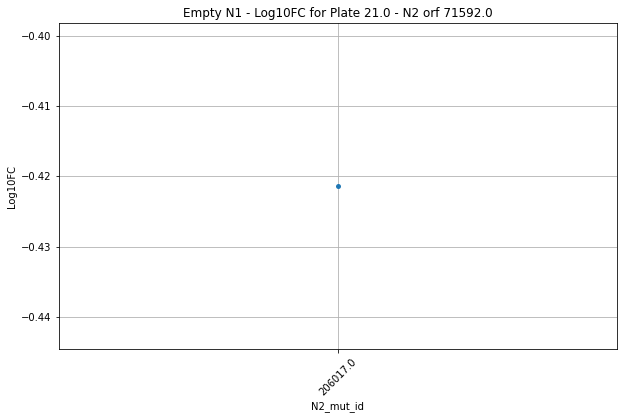

71892.0
	 17.0


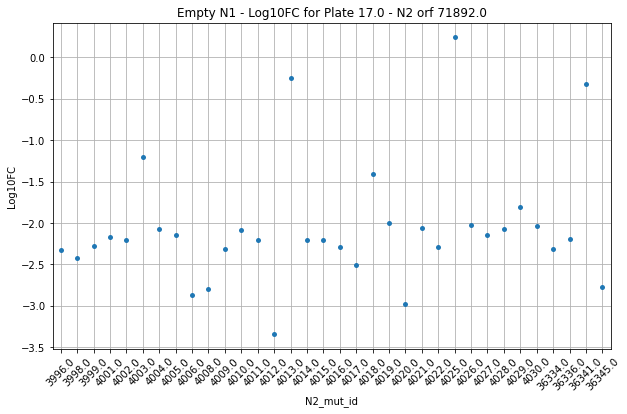

100016069.0
	 16.0


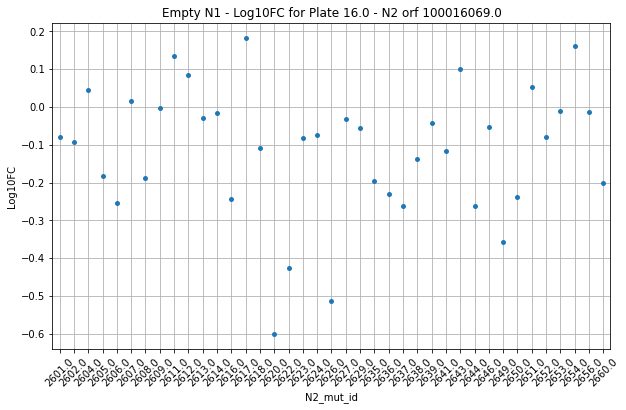

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

for N2_orf_id, df in retest_df[retest_df.variant_id == 'empty_N1'].groupby('N2_orf_id'):
    if N2_orf_id != 0:
        print(N2_orf_id)
    # if N2_orf_id == 4062:
        for pla, df_pla in df.groupby('retest_pla'):
            if pla > 5:
                print('\t',pla)
                wt_xp1 = df_pla[df_pla.N2_mut_id == 0].xp1.values[0]
                alleles_xp1 = df_pla[df_pla.N2_mut_id != 0].xp1.values
                log10fc_values = [np.log10(allele / wt_xp1) for allele in alleles_xp1]

                # Create a DataFrame for plotting
                plot_data = pd.DataFrame({
                    'N2_mut_id': df_pla[df_pla.N2_mut_id != 0].N2_mut_id.values,
                    'log10fc': log10fc_values
                })

                # Plotting
                plt.figure(figsize=(10, 6))
                sns.stripplot(x='N2_mut_id', y='log10fc', data=plot_data, jitter=True)
                plt.title(f'Empty N1 - Log10FC for Plate {pla} - N2 orf {N2_orf_id}')
                plt.xticks(rotation=45)
                plt.xlabel('N2_mut_id')
                plt.ylabel('Log10FC')
                plt.grid(True)
                plt.show()

In [ ]:
allele_df[allele_df.perturbation_classes_2 == 'increased edge']

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
144,93345.0,12825,CLDN20,NaN,4062,PLP1,201422,9.0,H03,mN2Hapwtv2,...,False,1.595521,not_detected,1,1,1.500000,False,increased edge,increased edge,Moderate increase
152,93364.0,12825,CLDN20,NaN,4062,PLP1,201426,9.0,C06,mN2Hapwtv2,...,False,1.416251,not_detected,1,1,1.166667,False,increased edge,increased edge,Moderate increase
163,93382.0,4935,SLC18A1,NaN,4062,PLP1,201422,9.0,E08,mN2Hapwtv2,...,False,-0.007949,not_detected,1,1,1.333333,False,increased edge,increased edge,Neutral
170,93390.0,12825,CLDN20,NaN,4062,PLP1,201423,9.0,E09,mN2Hapwtv2,...,False,-0.081575,not_detected,1,1,1.166667,False,increased edge,increased edge,Neutral
186,93422.0,4935,SLC18A1,NaN,4062,PLP1,201428,10.0,F01,mN2Hapwtv2,...,False,0.518004,not_detected,1,1,1.333333,False,increased edge,increased edge,Weak increase
199,93449.0,12825,CLDN20,NaN,4062,PLP1,201428,10.0,A05,mN2Hapwtv2,...,False,1.250824,not_detected,1,1,1.166667,False,increased edge,increased edge,Moderate increase
202,93456.0,4935,SLC18A1,NaN,4062,PLP1,201431,10.0,H05,mN2Hapwtv2,...,False,0.570144,not_detected,1,1,2.666667,False,increased edge,increased edge,Weak increase
213,93468.0,13628,KLRC1,NaN,4062,PLP1,201431,10.0,D07,mN2Hapwtv2,...,False,0.884437,not_detected,1,1,1.250000,False,increased edge,increased edge,Weak increase
224,93488.0,2012,LHFPL5,NaN,4062,PLP1,201429,10.0,A10,mN2Hapwtv2,...,False,0.794926,not_detected,1,1,1.166667,False,increased edge,increased edge,Weak increase
226,93493.0,12825,CLDN20,NaN,4062,PLP1,201431,10.0,F10,mN2Hapwtv2,...,False,1.014073,not_detected,1,1,2.000000,False,increased edge,increased edge,Moderate increase


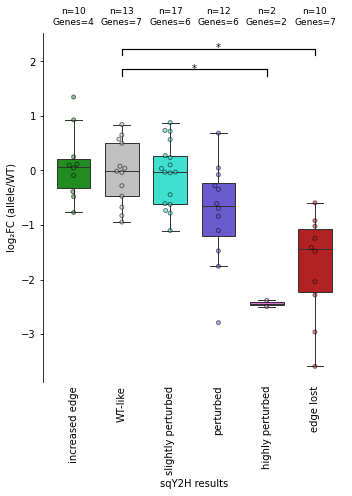

In [ ]:

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.70, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H results')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['N2_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

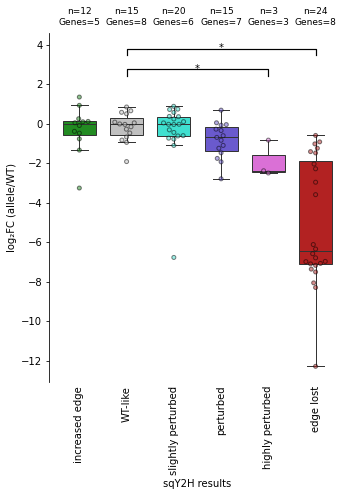

In [ ]:

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df_new_seq[
    (allele_df_new_seq.repeat_zscore == False)
    &
    (allele_df_new_seq.WT_detected == True)
    &
    (allele_df_new_seq.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.70, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H results')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['N2_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

In [ ]:
plot_df[(plot_df.perturbation_classes_2 == 'edge lost')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,n2h_binary_2,ratio,perturbed,perturbation_classes,perturbation_classes_2
153,93316.0,7675,NMNAT1,NaN,7675,NMNAT1,202588,8.0,B08,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
161,93334.0,5793,MS4A3,NaN,4062,PLP1,201424,9.0,E02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
171,93356.0,6520,IFT43,NaN,9866,ZMYND10,216927,9.0,C05,mN2Hapwtv2,...,1,1.0,0,NaN,1,1,0.0,True,edge lost,edge lost
208,93419.0,3731,PRPS1,NaN,3731,PRPS1,201248,10.0,C01,mN2Hapwtv2,...,1,1.0,0,NaN,1,1,0.0,True,edge lost,edge lost
312,93631.0,2654,FBP1,NaN,2654,FBP1,214309,12.0,D04,mN2Hapwtv2,...,1,2.0,1,6.0,1,1,0.0,True,edge lost,edge lost
416,93887.0,6552,MAGEA8,NaN,2713,MLH1,981,15.0,E01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
417,93888.0,6552,MAGEA8,NaN,2713,MLH1,200818,15.0,F01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
420,93892.0,6552,MAGEA8,NaN,2713,MLH1,200798,15.0,B02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
421,93896.0,6552,MAGEA8,NaN,2713,MLH1,473,15.0,F02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost
422,93898.0,6552,MAGEA8,NaN,2713,MLH1,967,15.0,H02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.0,True,edge lost,edge lost


In [ ]:
plot_df[(plot_df.perturbation_classes_2 == 'slightly perturbed')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,n2h_binary_2,ratio,perturbed,perturbation_classes,perturbation_classes_2
136,93261.0,7675,NMNAT1,NaN,7675,NMNAT1,202590,8.0,C01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.714286,False,slightly perturbed,slightly perturbed
167,93344.0,5793,MS4A3,NaN,4062,PLP1,201422,9.0,G03,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.857143,False,similar,slightly perturbed
238,93470.0,5793,MS4A3,NaN,4062,PLP1,201430,10.0,G07,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.857143,False,similar,slightly perturbed
298,93611.0,2920,GFAP,NaN,2920,GFAP,214433,12.0,G01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.777778,False,slightly perturbed,slightly perturbed
299,93612.0,2920,GFAP,NaN,2920,GFAP,214442,12.0,H01,mN2Hapwtv2,...,1,1.0,0,NaN,1,1,0.777778,False,slightly perturbed,slightly perturbed
308,93627.0,2920,GFAP,NaN,2920,GFAP,214430,12.0,H03,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.888889,False,similar,slightly perturbed
339,93681.0,2920,GFAP,NaN,2920,GFAP,214397,12.0,F10,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.888889,False,similar,slightly perturbed
360,93739.0,2920,GFAP,NaN,2920,GFAP,214445,13.0,B06,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.888889,False,similar,slightly perturbed
369,93762.0,2920,GFAP,NaN,2920,GFAP,214444,13.0,A09,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.888889,False,similar,slightly perturbed
381,93802.0,4621,KXD1,NaN,4723,TPM1,201733,14.0,B02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.937500,False,similar,slightly perturbed


In [ ]:
plot_df[plot_df.N2_symbol == 'TMEM43']

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,n2h_binary_2,ratio,perturbed,perturbation_classes,perturbation_classes_2
702,94649.0,361,GRAMD2B,NaN,3438,TMEM43,201183,23.0,C03,mN2Hapwtv2,...,1,99.0,1,1.0,1,0,0.875,False,similar,slightly perturbed
705,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.000,True,edge lost,edge lost
707,94682.0,361,GRAMD2B,NaN,3438,TMEM43,201175,23.0,D07,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,0.875,False,similar,slightly perturbed


In [ ]:
plot_df[(plot_df.perturbation_classes_2 == 'increased edge')]

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,n2h_binary,n2h_binary_2,ratio,perturbed,perturbation_classes,perturbation_classes_2
301,93615.0,2920,GFAP,NaN,2920,GFAP,214388,12.0,C02,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.111111,False,increased edge,increased edge
322,93649.0,2920,GFAP,NaN,2920,GFAP,214394,12.0,F06,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.222222,False,increased edge,increased edge
414,93883.0,6552,MAGEA8,NaN,2713,MLH1,838,15.0,A01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.428571,False,increased edge,increased edge
415,93886.0,6552,MAGEA8,NaN,2713,MLH1,200856,15.0,D01,mN2Hapwtv2,...,1,2.0,1,1.0,1,1,1.285714,False,increased edge,increased edge
425,93905.0,6552,MAGEA8,NaN,2713,MLH1,919,15.0,G03,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.285714,False,increased edge,increased edge
426,93907.0,6552,MAGEA8,NaN,2713,MLH1,200868,15.0,A04,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.285714,False,increased edge,increased edge
427,93909.0,6552,MAGEA8,NaN,2713,MLH1,200850,15.0,C04,mN2Hapwtv2,...,1,1.0,1,5.0,1,1,1.285714,False,increased edge,increased edge
432,93932.0,6552,MAGEA8,NaN,2713,MLH1,200824,15.0,B07,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.571429,False,increased edge,increased edge
514,94162.0,2767,GALE,NaN,2767,GALE,214361,18.0,A01,mN2Hapwtv2,...,1,1.0,1,1.0,1,1,1.428571,False,increased edge,increased edge
563,94263.0,54668,KRT40,NaN,13939,KRT86,204120,19.0,H01,mN2Hapwtv2,...,1,1.0,0,NaN,1,1,1.500000,False,increased edge,increased edge


In [ ]:
allele_df.to_csv(f'{outputs_dir}/mN2H_allele_df.csv', index=False)

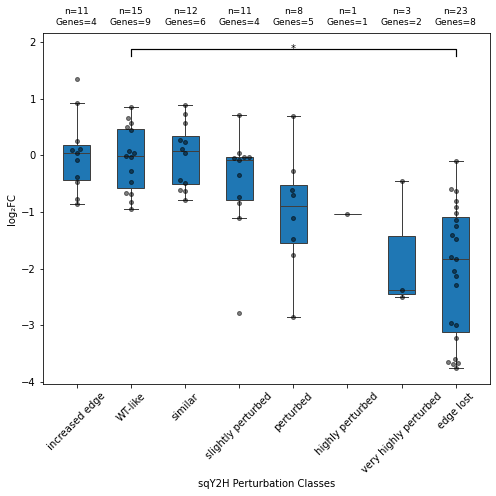

In [ ]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'similar',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'very highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes == plot_df.perturbation_classes]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(7,7))
sns.boxplot(
    x='perturbation_classes', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.5,  saturation=1
)
sns.swarmplot(
    x='perturbation_classes', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1
)

ax.set_xlabel('sqY2H Perturbation Classes')
ax.set_ylabel('log₂FC')
ax.tick_params(axis='x', rotation=45)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes == cat]
    n_edges = len(sub)
    n_genes = sub['N2_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )


plt.tight_layout()
plt.show()


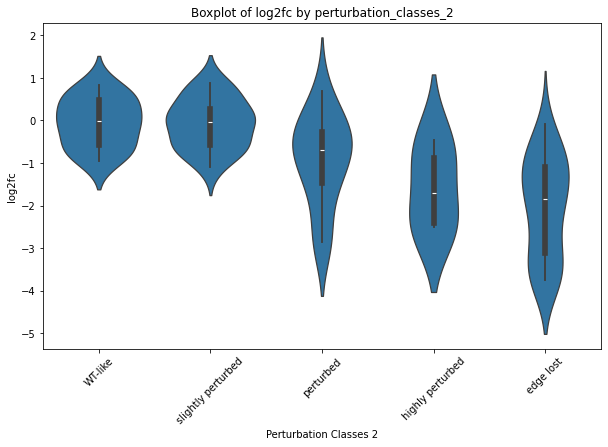

In [ ]:
# volcano plot


plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]

order = ['WT-like', 'slightly perturbed', 'perturbed', 'highly perturbed', 'edge lost']


plt.figure(figsize=(10, 6))
sns.violinplot(x='perturbation_classes_2', y='log2fc', data=plot_df_perturb, order=order)
plt.title('Boxplot of log2fc by perturbation_classes_2')
plt.xlabel('Perturbation Classes 2')
plt.ylabel('log2fc')
plt.xticks(rotation=45)
plt.show()


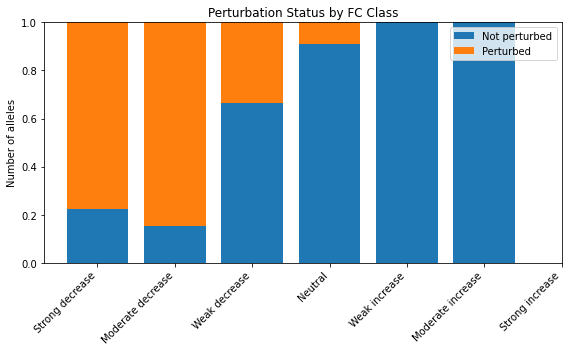

In [ ]:
import matplotlib.pyplot as plt

plot_df = allele_df[
    (allele_df.repeat_zscore == False) 
    &
    (allele_df.WT_detected == True)
                    ]

# 1) Tabulate counts of perturbed vs. not per class
counts = plot_df.groupby(['fc_class', 'perturbed']) \
                  .size() \
                  .unstack(fill_value=0)

# 2) (Optional) Enforce a biologically meaningful order
order = [
    'Strong decrease',
    'Moderate decrease',
    'Weak decrease',
    'Neutral',
    'Weak increase',
    'Moderate increase',
    'Strong increase'
]
counts = counts.reindex(order).fillna(0)

props = counts.div(counts.sum(axis=1), axis=0)

# 3) Build the stacked bar chart
plt.figure(figsize=(8, 5))
x = range(len(props))
not_pert = props[False].values
pert     = props[True].values

plt.bar(x, not_pert, label='Not perturbed')
plt.bar(x, pert, bottom=not_pert, label='Perturbed')

plt.xticks(x, props.index, rotation=45, ha='right')
plt.ylabel('Number of alleles')
plt.title('Perturbation Status by FC Class')
plt.legend()
plt.tight_layout()
plt.show()

# Final figure

In [ ]:
#wtpwt_normalized_df = pd.read_csv(f'{outputs_dir}/mN2H_wtpwt_allele_df.csv')
apwt_normalized_df = pd.read_csv(f'{outputs_dir}/mN2H_apwt_allele_df.csv')

keep_cols = ["variant_id", "avg_NLR", "repeat_zscore", "ppi_perturbation_class_04"]

## Pertubed vs not-perturbed

35.47428497257972


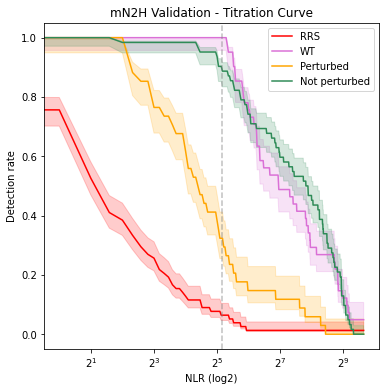

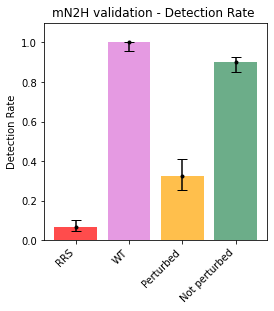

[0.0641025641025641, 1.0, 0.3235294117647059, 0.9032258064516129]

In [ ]:
# BINARY PPI PERTURBATION CLASS


#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)


positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold)].pair)
    

res_d = {}

for i in range(-8,800):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in [True, False]:
      pos = ((allele_df.perturbed == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
              (allele_df.WT_detected == True)&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbed == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
              (allele_df.WT_detected == True)&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', 'True', 'False']
cat_d = dict(zip(cats,['RRS','WT', 'Perturbed', 'Not perturbed']))
colors = ['r','orchid','orange','seagreen']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()
y

## Perturbed classes

35.47428497257972


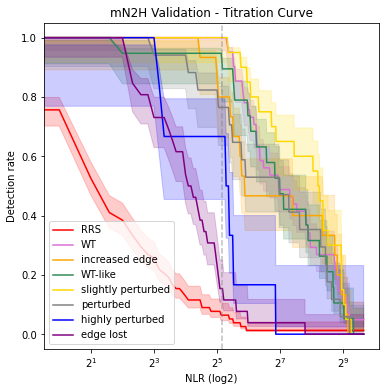

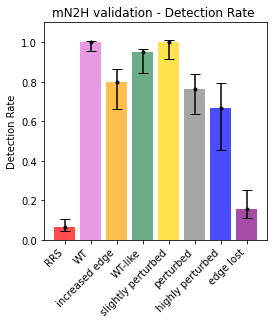

In [ ]:
## plot detection rate for different thresholds

#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold )].pair)

res_d = {}

for i in range(-8,800):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:
      pos = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()

In [ ]:
normalized_df.avg_NLR.max(), normalized_df.avg_NLR.min()

(997.4441635990423, 0.00018480051839217168)

35.47428497257972


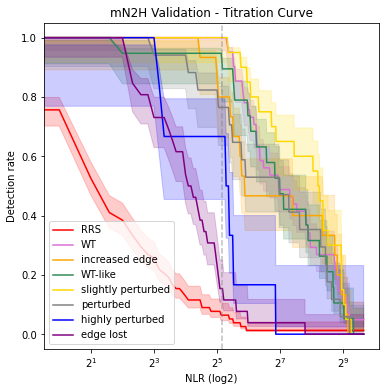

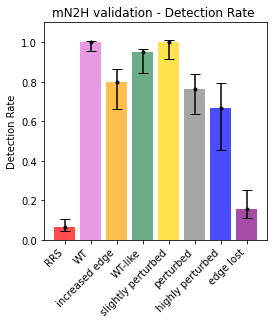

In [ ]:
## plot detection rate for different thresholds

#limited to WT positive pairs
rrs_mean = np.mean(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)
rrs_std = np.std(normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.avg_NLR < 200)].avg_NLR)

threshold = 2.326*rrs_std+rrs_mean
print(threshold)

positive_wt_pairs = set(normalized_df[(normalized_df.variant_id == 'wt')&(normalized_df.avg_NLR >= threshold )].pair)

res_d = {}

for i in range(-8,800):
# for i in range(-8,1000):
    trsh = i
    
    rrs_pos, rrs_neg = (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR >= trsh).sum(), (normalized_df[(normalized_df.variant_id == 'RRS')].avg_NLR < trsh).sum()
    rrs_lower, rrs_upper = stats.beta.interval(0.6827, rrs_pos + 1, rrs_neg + 1)
    rrs_rate = rrs_pos/(rrs_pos+rrs_neg)
    
    wt_pos = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)
                            ].avg_NLR >= trsh).sum()

    wt_neg = (normalized_df[(normalized_df.variant_id == 'wt')&
                            (normalized_df.pair.isin(positive_wt_pairs))&
                            (normalized_df.avg_NLR >= threshold)&
                            (normalized_df.repeat_zscore == False)].avg_NLR < trsh).sum()

    wt_lower, wt_upper = stats.beta.interval(0.6827, wt_pos + 1, wt_neg + 1)
    wt_rate = wt_pos/(wt_pos+wt_neg)
    res_d[i] = {'trsh':trsh,'rrs_rate':rrs_rate, 'rrs_lower':rrs_lower, 'rrs_upper':rrs_upper,'wt_rate':wt_rate, 'wt_lower':wt_lower, 'wt_upper':wt_upper}
    
    for cat in ["increased edge",
                'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]:
      pos = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR >= trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      neg = ((allele_df.perturbation_classes_2 == cat)&
             (allele_df.avg_NLR < trsh)&
               (allele_df.pair.isin(positive_wt_pairs))&
               (allele_df.repeat_zscore == False)).sum()
      lower, upper = stats.beta.interval(0.6827, pos + 1, neg + 1)
      rate = pos/(pos+neg)
      res_d[i][f'{cat}_rate'] = rate
      res_d[i][f'{cat}_lower'] = lower
      res_d[i][f'{cat}_upper'] = upper

rate_df = pd.DataFrame(res_d).T

plt.figure(figsize=(6,6))
plt.title('mN2H Validation - Titration Curve')
cats = ['rrs','wt', "increased edge",
        'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]
cat_d = dict(zip(cats,['RRS','WT',"increased edge",
                       'WT-like',
    "slightly perturbed",
    "perturbed",
    "highly perturbed",
    'edge lost'
    ]))
colors = ['r','orchid','orange','seagreen','gold','gray','b','purple','k','g']

for cat,color in zip(cats,colors):

    ax = sns.lineplot(data=rate_df, x='trsh' , y=f'{cat}_rate', color=color, label=cat_d[cat])
    ax.fill_between(rate_df.trsh, rate_df[f'{cat}_upper'], rate_df[f'{cat}_lower'], alpha=0.2, color=color)

plt.axvline(x=threshold, color='grey', linestyle='--', alpha=0.5)

#plt.xlim((0,7))
plt.ylim((-0.05,1.05))
plt.xlabel('NLR (log2)')
plt.ylabel('Detection rate')
plt.xscale('log', base=2)
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_titration_curve.png', dpi=300,  bbox_inches='tight')
plt.show()

plt.figure(figsize=(4,4))
plt.title('mN2H validation - Detection Rate ')
lower_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_lower'])  for cat in cats]
upper_error = [abs(res_d[int(threshold)][f'{cat}_rate'] - res_d[int(threshold)][f'{cat}_upper'])  for cat in cats]
asymmetric_error = np.array(list(zip(lower_error, upper_error))).T

x = cat_d.values()
y = [e[1] for e in res_d[int(threshold)].items() if 'rate' in e[0]]

plt.bar(x, y, color = colors,alpha=0.7)  #color=['black', 'red', 'green', 'blue', 'cyan']
plt.errorbar(x, y, yerr=asymmetric_error, fmt='.', color = 'black',ecolor = 'black', capsize=5)
plt.ylim((0,1.1))
plt.ylabel('Detection Rate')
plt.xticks(rotation = 45, ha='right')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.pdf',  bbox_inches='tight')
# plt.savefig(f'{folder_path}/mN2Hapwt_validation_detection_rate.png', dpi=300,  bbox_inches='tight')
plt.show()

# compare with yN2H

In [ ]:
yN2H_allele_df = pd.read_csv(f'{yN2H_output_dir}/yN2H_allele_df.csv')
yN2H_allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,False,-0.248643,not_detected,1,1,0.000000,True,edge lost,edge lost,edge lost
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,True,-3.917612,decrease_ppi,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,False,-1.136611,not_detected,1,1,NaN,NaN,NaN,NaN,NaN
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,True,-0.063610,no_perturbation,1,1,0.875000,False,similar,slightly perturbed,perturbed
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,False,1.718716,not_detected,1,1,NaN,False,WT edge lost,WT edge lost,perturbed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,True,-0.810454,no_perturbation,1,1,0.909091,False,similar,slightly perturbed,perturbed
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,True,-1.998789,no_perturbation,1,1,0.500000,False,perturbed,perturbed,perturbed
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,True,-1.440629,no_perturbation,1,1,0.000000,True,edge lost,edge lost,edge lost
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,False,0.248562,not_detected,1,1,1.166667,False,increased edge,increased edge,perturbed


In [ ]:
allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,WT_detected,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,False,1.455811,not_detected,1,1,NaN,NaN,NaN,NaN,Moderate increase
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,True,0.807605,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak increase
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,True,-0.929932,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak decrease
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,True,1.875172,no_perturbation,1,1,NaN,NaN,NaN,NaN,Moderate increase
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,False,3.983833,not_detected,1,1,inf,False,WT edge lost,WT edge lost,Strong increase
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,94622.0,1256,KLHL3,NaN,11305,CUL3,217226,22.0,G11,mN2Hapwtv2,...,False,-5.508399,not_detected,1,1,NaN,NaN,NaN,NaN,Strong decrease
560,94630.0,3608,CYB561,NaN,3086,GOSR2,201084,22.0,G12,mN2Hapwtv2,...,False,5.388247,not_detected,1,1,NaN,NaN,NaN,NaN,Strong increase
561,94635.0,361,GRAMD2B,NaN,3438,TMEM43,201177,23.0,E01,mN2Hapwtv2,...,True,-0.214879,no_perturbation,1,1,1.000,False,WT-like,WT-like,Neutral
562,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,True,-0.601777,no_perturbation,1,1,0.000,True,edge lost,edge lost,Weak decrease


In [ ]:
yN2H_allele_df['pair_mut'] = [f'{N1}_{N2}_{mut}' for N1, N2, mut in zip(yN2H_allele_df.ad_orf_id, yN2H_allele_df.db_orf_id, yN2H_allele_df.db_mut_id)]
allele_df['pair_mut'] = [f'{N1}_{N2}_{mut}' for N1, N2, mut in zip(allele_df.N1_orf_id, allele_df.N2_orf_id, allele_df.N2_mut_id)]

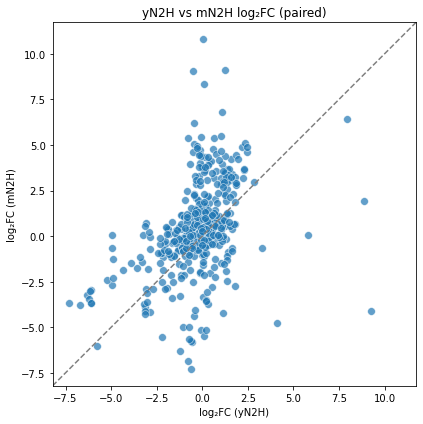

Pearson r = 0.42


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_yN2H'})
df2 = allele_df[['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')


# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x='log2fc_yN2H', y='log2fc_mN2H',
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel('log₂FC (yN2H)')
ax.set_ylabel('log₂FC (mN2H)')
ax.set_title('yN2H vs mN2H log₂FC (paired)')

plt.tight_layout()
plt.show()

r = df_merge['log2fc_yN2H'].corr(df_merge['log2fc_mN2H'])
print(f"Pearson r = {r:.2f}")


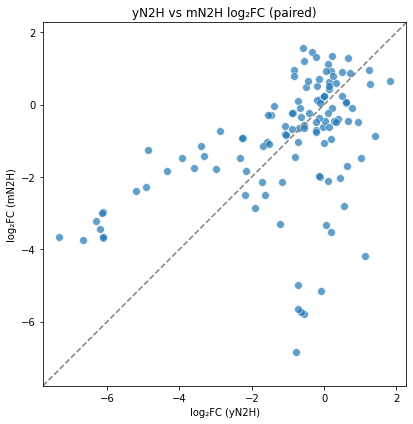

Pearson r = 0.44


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    # &
    # (yN2H_allele_df.repeat_zscore == False)
    # &
    # (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_yN2H'})
df2 = allele_df[
    (allele_df.WT_detected == True)
    # &
    # (allele_df.repeat_zscore == False)
    # &
    # (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')


# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x='log2fc_yN2H', y='log2fc_mN2H',
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel('log₂FC (yN2H)')
ax.set_ylabel('log₂FC (mN2H)')
ax.set_title('yN2H vs mN2H log₂FC (paired)')

plt.tight_layout()
plt.show()

r = df_merge['log2fc_yN2H'].corr(df_merge['log2fc_mN2H'])
print(f"Pearson r = {r:.2f}")


In [ ]:
yN2H_allele_df

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,pair_mut
0,71963,MBD3L1,2713,MLH1,981,allele,4,H05,96,82.0,...,-0.248643,not_detected,1,1,0.000000,True,edge lost,edge lost,edge lost,71963_2713_981
1,71892,TH,71892,TH,4005,allele,4,E05,1092,254.0,...,-3.917612,decrease_ppi,1,1,0.125000,True,very highly perturbed,highly perturbed,perturbed,71892_71892_4005
2,10677,KPNA5,2713,MLH1,200834,allele,4,G02,261,76.0,...,-1.136611,not_detected,1,1,NaN,NaN,NaN,NaN,NaN,10677_2713_200834
3,361,GRAMD2B,3438,TMEM43,201175,allele,4,C02,6641,1669.0,...,-0.063610,no_perturbation,1,1,0.875000,False,similar,slightly perturbed,perturbed,361_3438_201175
4,11452,WASHC1,4723,TPM1,201733,allele,4,E01,549,117.0,...,1.718716,not_detected,1,1,NaN,False,WT edge lost,WT edge lost,perturbed,11452_4723_201733
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,5093,TMEM79,5723,SFTPC,201963,allele,37,C07,2561,1875.0,...,-0.810454,no_perturbation,1,1,0.909091,False,similar,slightly perturbed,perturbed,5093_5723_201963
1166,11130,SLC35E3,4062,PLP1,201433,allele,37,D07,1044,1305.0,...,-1.998789,no_perturbation,1,1,0.500000,False,perturbed,perturbed,perturbed,11130_4062_201433
1167,4946,PTPRN,4062,PLP1,201423,allele,37,F07,1875,1772.0,...,-1.440629,no_perturbation,1,1,0.000000,True,edge lost,edge lost,edge lost,4946_4062_201423
1168,10441,RAB28,71337,ACSF3,205771,allele,37,F08,151,206.0,...,0.248562,not_detected,1,1,1.166667,False,increased edge,increased edge,perturbed,10441_71337_205771


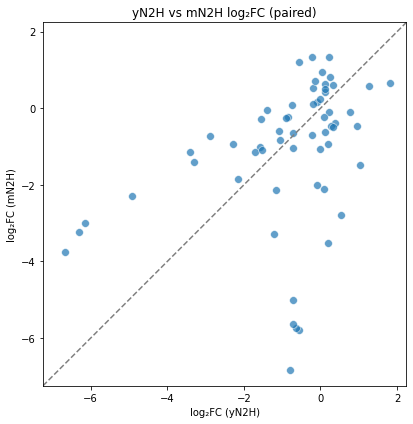

Pearson r = 0.36


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    # &
    # (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_yN2H'})
df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    # &
    # (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')


# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x='log2fc_yN2H', y='log2fc_mN2H',
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel('log₂FC (yN2H)')
ax.set_ylabel('log₂FC (mN2H)')
ax.set_title('yN2H vs mN2H log₂FC (paired)')

plt.tight_layout()
plt.show()

r = df_merge['log2fc_yN2H'].corr(df_merge['log2fc_mN2H'])
print(f"Pearson r = {r:.2f}")


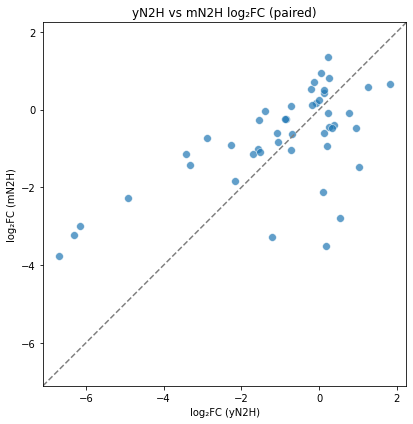

Pearson r = 0.61
46


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_yN2H'})
df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc']].rename(columns={'log2fc':'log2fc_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')


# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x='log2fc_yN2H', y='log2fc_mN2H',
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel('log₂FC (yN2H)')
ax.set_ylabel('log₂FC (mN2H)')
ax.set_title('yN2H vs mN2H log₂FC (paired)')

plt.tight_layout()
plt.show()

r = df_merge['log2fc_yN2H'].corr(df_merge['log2fc_mN2H'])
print(f"Pearson r = {r:.2f}")
print(len(df_merge))


In [ ]:
# identify weird alleles

weird_alleles = df_merge[(df_merge.log2fc_yN2H > -2)
                         &
                         (df_merge.log2fc_mN2H < -1.4)
                         ]
weird_alleles_list = weird_alleles.pair_mut.tolist()

weird_alleles

,pair_mut,log2fc_yN2H,log2fc_mN2H
5,3818_4723_201726,0.188770,-3.520723
10,2533_55246_219180,1.027923,-1.479376
29,2533_55246_219175,-1.216171,-3.287509
31,2920_2920_214409,0.542872,-2.790723
42,9501_5723_201963,0.103375,-2.116052


In [ ]:
yN2H_allele_df[yN2H_allele_df.pair_mut.isin(weird_alleles_list)]

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,variant_id,retest_pla,retest_pos,N2H_raw_r01,N2H_raw_r02,...,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,perturbation_binary,pair_mut
139,3818,PSMC5,4723,TPM1,201726,allele,12,A04,941,955.0,...,0.218028,no_perturbation,1,1,NaN,NaN,NaN,NaN,NaN,3818_4723_201726
173,2533,PYGB,55246,PYGL,219180,allele,11,C01,3317,7259.0,...,1.232298,no_perturbation,1,1,NaN,NaN,NaN,NaN,NaN,2533_55246_219180
654,2533,PYGB,55246,PYGL,219175,allele,14,G04,948,1078.0,...,-1.480102,no_perturbation,1,1,NaN,NaN,NaN,NaN,NaN,2533_55246_219175
799,2920,GFAP,2920,GFAP,214409,allele,26,E11,247,309.0,...,0.646025,no_perturbation,1,1,0.666667,False,slightly perturbed,perturbed,perturbed,2920_2920_214409
1123,9501,LSMEM2,5723,SFTPC,201963,allele,36,D06,13585,13406.0,...,0.114812,no_perturbation,1,1,NaN,NaN,NaN,NaN,NaN,9501_5723_201963


In [ ]:
mN2H_plotted_alleles = allele_df[
    (allele_df.repeat_zscore == False)
    &
    (allele_df.WT_detected == True)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ].pair_mut.to_list()

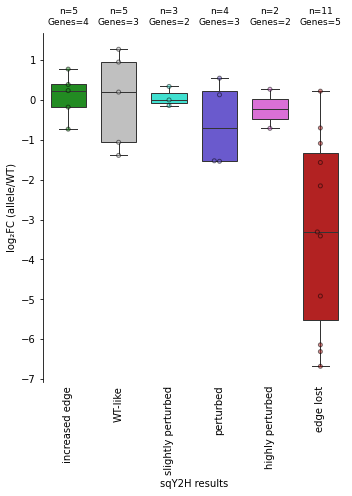

In [ ]:

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) fix your desired order
order = [
    'increased edge',
    'WT-like',
    'slightly perturbed',
    'perturbed',
    'highly perturbed',
    'edge lost'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'   # gray
]

palette = dict(zip(order, box_colors))


plot_df = yN2H_allele_df[
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    &
    (yN2H_allele_df.pair_mut.isin(mN2H_plotted_alleles))
    ]

plot_df_perturb = plot_df[plot_df.perturbation_classes_2 == plot_df.perturbation_classes_2]


# 2) select the DF you want
df_plot = plot_df_perturb.copy()

# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order, ax=ax, showfliers=False,
    width=0.70, palette=palette, saturation=1
)
sns.swarmplot(
    x='perturbation_classes_2', y='log2fc',
    data=df_plot, order=order,
    color='black', alpha=0.5, size=4, ax=ax, 
    edgecolor='black', linewidth=1, palette=palette
)

ax.set_xlabel('sqY2H results')
ax.set_ylabel('log₂FC (allele/WT)')
ax.tick_params(axis='x', rotation=90)



# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in pairs:
    x = df_plot.loc[df_plot.perturbation_classes_2==g1, 'log2fc']
    y = df_plot.loc[df_plot.perturbation_classes_2==g2, 'log2fc']
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot['log2fc'].max()
y_min = df_plot['log2fc'].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.perturbation_classes_2 == cat]
    n_edges = len(sub)
    n_genes = sub['db_orf_id'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()


## controls

In [ ]:
allele_df

,retest_id,N1_orf_id,N1_symbol,N1_mut_id,N2_orf_id,N2_symbol,N2_mut_id,retest_pla,retest_pos,retest_batch,...,z_perturbation,z_cat,N1_conf,N2_conf,ratio,perturbed,perturbation_classes,perturbation_classes_2,fc_class,pair_mut
0,93035.0,2838,TMEM248,NaN,9634,CLDN19,216880,5.0,A08,mN2Hapwtv2,...,1.455811,not_detected,1,1,NaN,NaN,NaN,NaN,Moderate increase,2838_9634_216880
1,93037.0,1198,TNFSF14,NaN,9634,CLDN19,216880,5.0,C08,mN2Hapwtv2,...,0.807605,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak increase,1198_9634_216880
2,93043.0,7201,RAD51D,NaN,13571,XRCC2,218098,5.0,A09,mN2Hapwtv2,...,-0.929932,no_perturbation,1,1,NaN,NaN,NaN,NaN,Weak decrease,7201_13571_218098
3,93044.0,9955,FCGR1A,NaN,9634,CLDN19,216880,5.0,B09,mN2Hapwtv2,...,1.875172,no_perturbation,1,1,NaN,NaN,NaN,NaN,Moderate increase,9955_9634_216880
4,93045.0,56141,KRT31,NaN,55855,KRT2,219419,5.0,C09,mN2Hapwtv2,...,3.983833,not_detected,1,1,inf,False,WT edge lost,WT edge lost,Strong increase,56141_55855_219419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
559,94622.0,1256,KLHL3,NaN,11305,CUL3,217226,22.0,G11,mN2Hapwtv2,...,-5.508399,not_detected,1,1,NaN,NaN,NaN,NaN,Strong decrease,1256_11305_217226
560,94630.0,3608,CYB561,NaN,3086,GOSR2,201084,22.0,G12,mN2Hapwtv2,...,5.388247,not_detected,1,1,NaN,NaN,NaN,NaN,Strong increase,3608_3086_201084
561,94635.0,361,GRAMD2B,NaN,3438,TMEM43,201177,23.0,E01,mN2Hapwtv2,...,-0.214879,no_perturbation,1,1,1.000,False,WT-like,WT-like,Neutral,361_3438_201177
562,94674.0,361,GRAMD2B,NaN,3438,TMEM43,201179,23.0,D06,mN2Hapwtv2,...,-0.601777,no_perturbation,1,1,0.000,True,edge lost,edge lost,Weak decrease,361_3438_201179


### empty N1

#### xp1

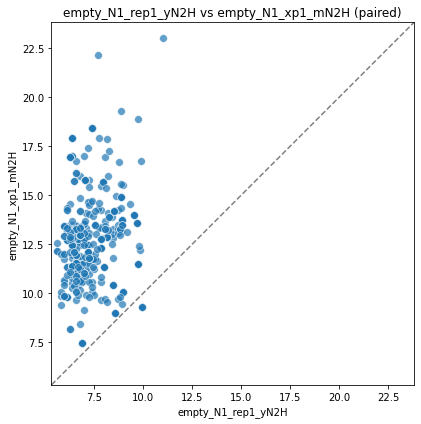

Pearson r = 0.17


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N1_rep1_yN2H'
var_2 = 'empty_N1_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2])
print(f"Pearson r = {r:.2f}")


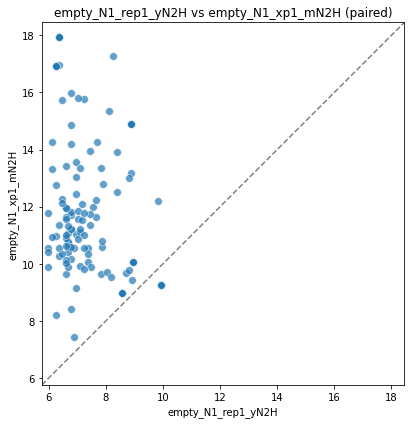

Pearson r = -0.20


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    # &
    # (yN2H_allele_df.repeat_zscore == False)
    # &
    # (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    # &
    # (allele_df.repeat_zscore == False)
    # &
    # (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N1_rep1_yN2H'
var_2 = 'empty_N1_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2])
print(f"Pearson r = {r:.2f}")


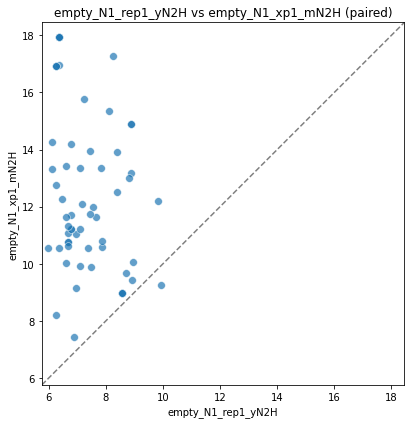

Pearson r = -0.25


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    # &
    # (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    # &
    # (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N1_rep1_yN2H'
var_2 = 'empty_N1_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2])
print(f"Pearson r = {r:.2f}")


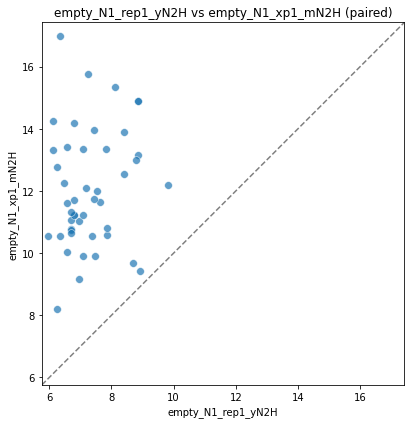

Pearson r = 0.15


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N1_rep1_yN2H'
var_2 = 'empty_N1_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2])
print(f"Pearson r = {r:.2f}")


#### xp2

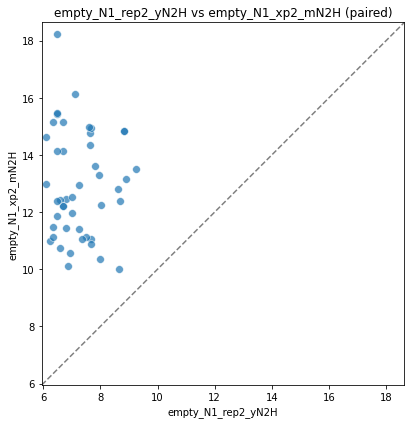

Pearson r = -0.03


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N1_rep2_yN2H'
var_2 = 'empty_N1_xp2_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2])
print(f"Pearson r = {r:.2f}")


### empty N2

#### xp1

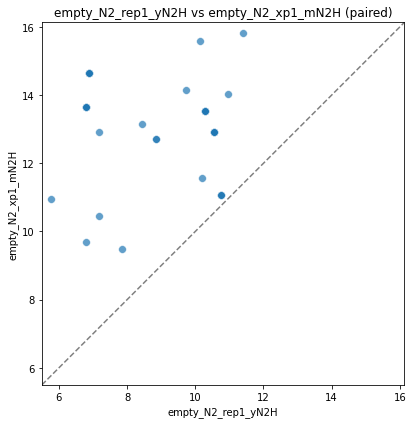

spearman r = -0.31


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N2_rep1_yN2H'
var_2 = 'empty_N2_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2], method='spearman')
print(f"spearman r = {r:.2f}")


#### xp2

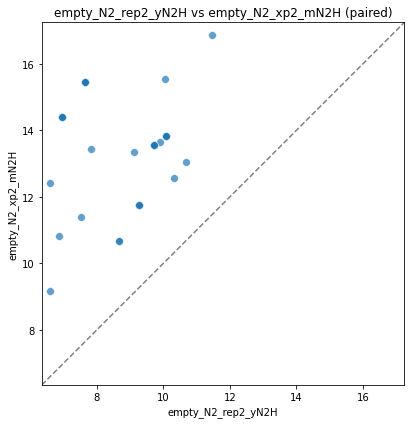

spearman r = -0.01


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N2_rep2_yN2H'
var_2 = 'empty_N2_xp2_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2], method='spearman')
print(f"spearman r = {r:.2f}")


#### xp1/xp2

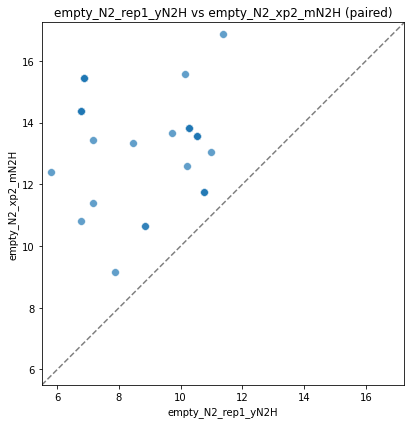

spearman r = -0.34


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N2_rep1_yN2H'
var_2 = 'empty_N2_xp2_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2], method='spearman')
print(f"spearman r = {r:.2f}")


#### xp2/xp1

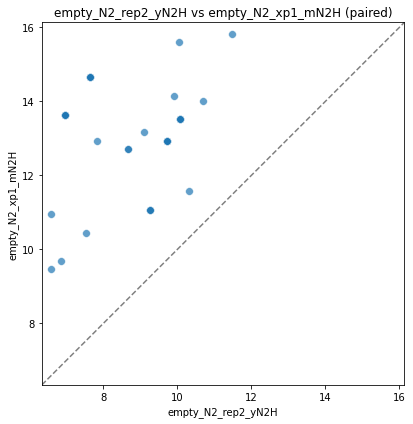

spearman r = 0.05


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) select only the columns you need & rename
df1 = yN2H_allele_df[
    (yN2H_allele_df.WT_detected == True)
    &
    (yN2H_allele_df.repeat_zscore == False)
    &
    (yN2H_allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_rep1', 'empty_N2_rep1', 'empty_N1_rep2', 'empty_N2_rep2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_yN2H',
                                                      'empty_N1_rep1':'empty_N1_rep1_yN2H', 
                                                      'empty_N2_rep1':'empty_N2_rep1_yN2H',
                                                      'empty_N1_rep2':'empty_N1_rep2_yN2H',
                                                      'empty_N2_rep2':'empty_N2_rep2_yN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_yN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_yN2H'})

df2 = allele_df[
    (allele_df.WT_detected == True)
    &
    (allele_df.repeat_zscore == False)
    &
    (allele_df.log10fc_empty_N1.between(-1,1))
    ][['pair_mut','log2fc','empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2', 'empty_N2_xp2',
       'max_ctrl_r1', 'max_ctrl_r2']].rename(columns={'log2fc':'log2fc_mN2H',
                                                      'empty_N1_xp1':'empty_N1_xp1_mN2H', 
                                                      'empty_N2_xp1':'empty_N2_xp1_mN2H',
                                                      'empty_N1_xp2':'empty_N1_xp2_mN2H',
                                                      'empty_N2_xp2':'empty_N2_xp2_mN2H',
                                                      'max_ctrl_r1':'max_ctrl_r1_mN2H',
                                                      'max_ctrl_r2':'max_ctrl_r2_mN2H'})

# 2) inner‐merge to keep only pair_mut present in both
df_merge = pd.merge(df1, df2, on='pair_mut', how='inner')

var_1 = 'empty_N2_rep2_yN2H'
var_2 = 'empty_N2_xp1_mN2H'

df_merge[var_1] = np.log2(df_merge[var_1])
df_merge[var_2] = np.log2(df_merge[var_2])

# after df_merge is ready…
plt.figure(figsize=(6,6))
ax = sns.scatterplot(
    data=df_merge,
    x=var_1, y=var_2,
    edgecolor='w', s=60, alpha=0.7
)

# 1) compute unified limits
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
lo = min(x0, y0)
hi = max(x1, y1)

# 2) apply to both axes
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)

# 3) enforce square aspect
ax.set_aspect('equal', adjustable='box')

# 4) set logarithmic scale
# ax.set_xscale('log')
# ax.set_yscale('log')


# optional: identity line
ax.plot([lo, hi], [lo, hi], '--', color='gray')

ax.set_xlabel(f'{var_1}')
ax.set_ylabel(f'{var_2}')
ax.set_title(f'{var_1} vs {var_2} (paired)')

plt.tight_layout()
plt.show()

r = df_merge[var_1].corr(df_merge[var_2], method='spearman')
print(f"spearman r = {r:.2f}")
